In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    roc_auc_score,roc_curve,
    precision_recall_curve,average_precision_score
)
# Classification models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.naive_bayes import GaussianNB

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier


In [50]:
df = pd.read_csv('/content/Adult Census Income.csv', na_values='?')
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,NaN,77053,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,NaN,186061,Some-college,10,Widowed,NaN,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [52]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [53]:
df.describe(include=object)

,workclass,education,marital.status,occupation,relationship,race,sex,native.country,income
count,30725,32561,32561,30718,32561,32561,32561,31978,32561
unique,8,16,7,14,6,5,2,41,2
top,Private,HS-grad,Married-civ-spouse,Prof-specialty,Husband,White,Male,United-States,<=50K
freq,22696,10501,14976,4140,13193,27816,21790,29170,24720


In [54]:
cat_col=['workclass', 'education', 'marital.status','occupation', 'relationship', 'race', 'sex', 'native.country']
for col in cat_col:
    print(f"\nUnique values in {col}:")
    print(df[col].unique())
    print("-" * 50)


Unique values in workclass:
[nan 'Private' 'State-gov' 'Federal-gov' 'Self-emp-not-inc' 'Self-emp-inc'
 'Local-gov' 'Without-pay' 'Never-worked']
--------------------------------------------------

Unique values in education:
['HS-grad' 'Some-college' '7th-8th' '10th' 'Doctorate' 'Prof-school'
 'Bachelors' 'Masters' '11th' 'Assoc-acdm' 'Assoc-voc' '1st-4th' '5th-6th'
 '12th' '9th' 'Preschool']
--------------------------------------------------

Unique values in marital.status:
['Widowed' 'Divorced' 'Separated' 'Never-married' 'Married-civ-spouse'
 'Married-spouse-absent' 'Married-AF-spouse']
--------------------------------------------------

Unique values in occupation:
[nan 'Exec-managerial' 'Machine-op-inspct' 'Prof-specialty'
 'Other-service' 'Adm-clerical' 'Craft-repair' 'Transport-moving'
 'Handlers-cleaners' 'Sales' 'Farming-fishing' 'Tech-support'
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']
--------------------------------------------------

Unique values in relations

In [55]:
df.duplicated().sum()

np.int64(24)

In [56]:
df.drop_duplicates(inplace=True)

In [57]:
df.isnull().sum()

,0
age,0
workclass,1836
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,1843
relationship,0
race,0
sex,0


In [58]:
df.groupby('native.country')['race'].value_counts()

native.country  race              
Cambodia        Asian-Pac-Islander     18
                Black                   1
Canada          White                 119
                Asian-Pac-Islander      1
                Other                   1
                                     ... 
United-States   Asian-Pac-Islander    291
                Other                 129
Vietnam         Asian-Pac-Islander     65
                White                   2
Yugoslavia      White                  16
Name: count, Length: 108, dtype: int64

In [59]:
df['native.country'] = df.groupby('race')['native.country'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else df['native.country'].mode()[0])
)

In [60]:
imputer = SimpleImputer(strategy='most_frequent')

df[['occupation']] = imputer.fit_transform(df[['occupation']])

In [61]:
df.groupby('age')['workclass'].value_counts()

age  workclass       
17   Private             300
     Local-gov            14
     Self-emp-inc          7
     Self-emp-not-inc      6
     State-gov             2
                        ... 
88   Private               1
90   Private              27
     Local-gov             4
     Self-emp-not-inc      3
     Federal-gov           1
Name: count, Length: 411, dtype: int64

In [62]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 25, 40, 60, 100],
    labels=['Young', 'Adult', 'Middle_Age', 'Senior']
)

df['workclass'] = df.groupby(
    'age_group', observed=True
)['workclass'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else df['workclass'].mode()[0])
)

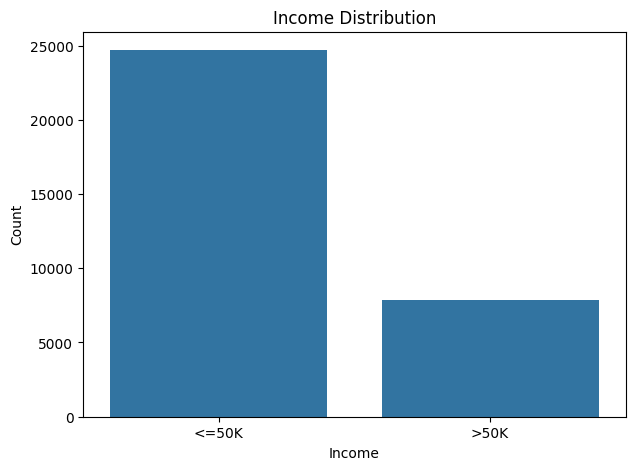

In [63]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='income')
plt.title('Income Distribution')
plt.xlabel('Income')
plt.ylabel('Count')
plt.show()

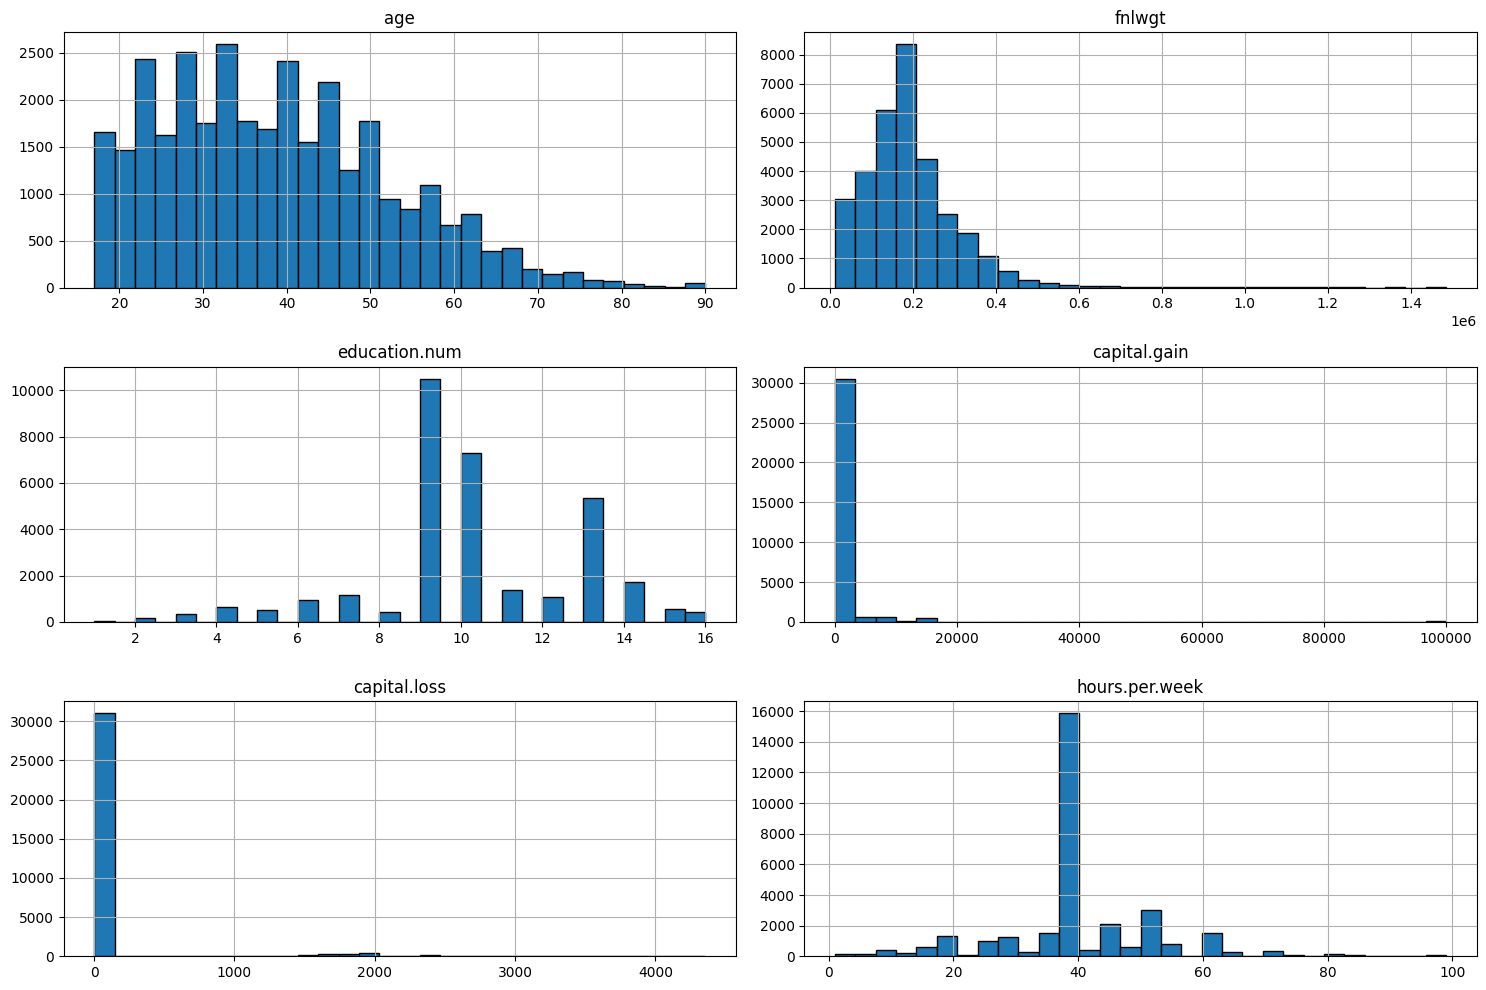

In [64]:
numerical_cols = [
    'age', 'fnlwgt', 'education.num',
    'capital.gain', 'capital.loss',
    'hours.per.week'
]

df[numerical_cols].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

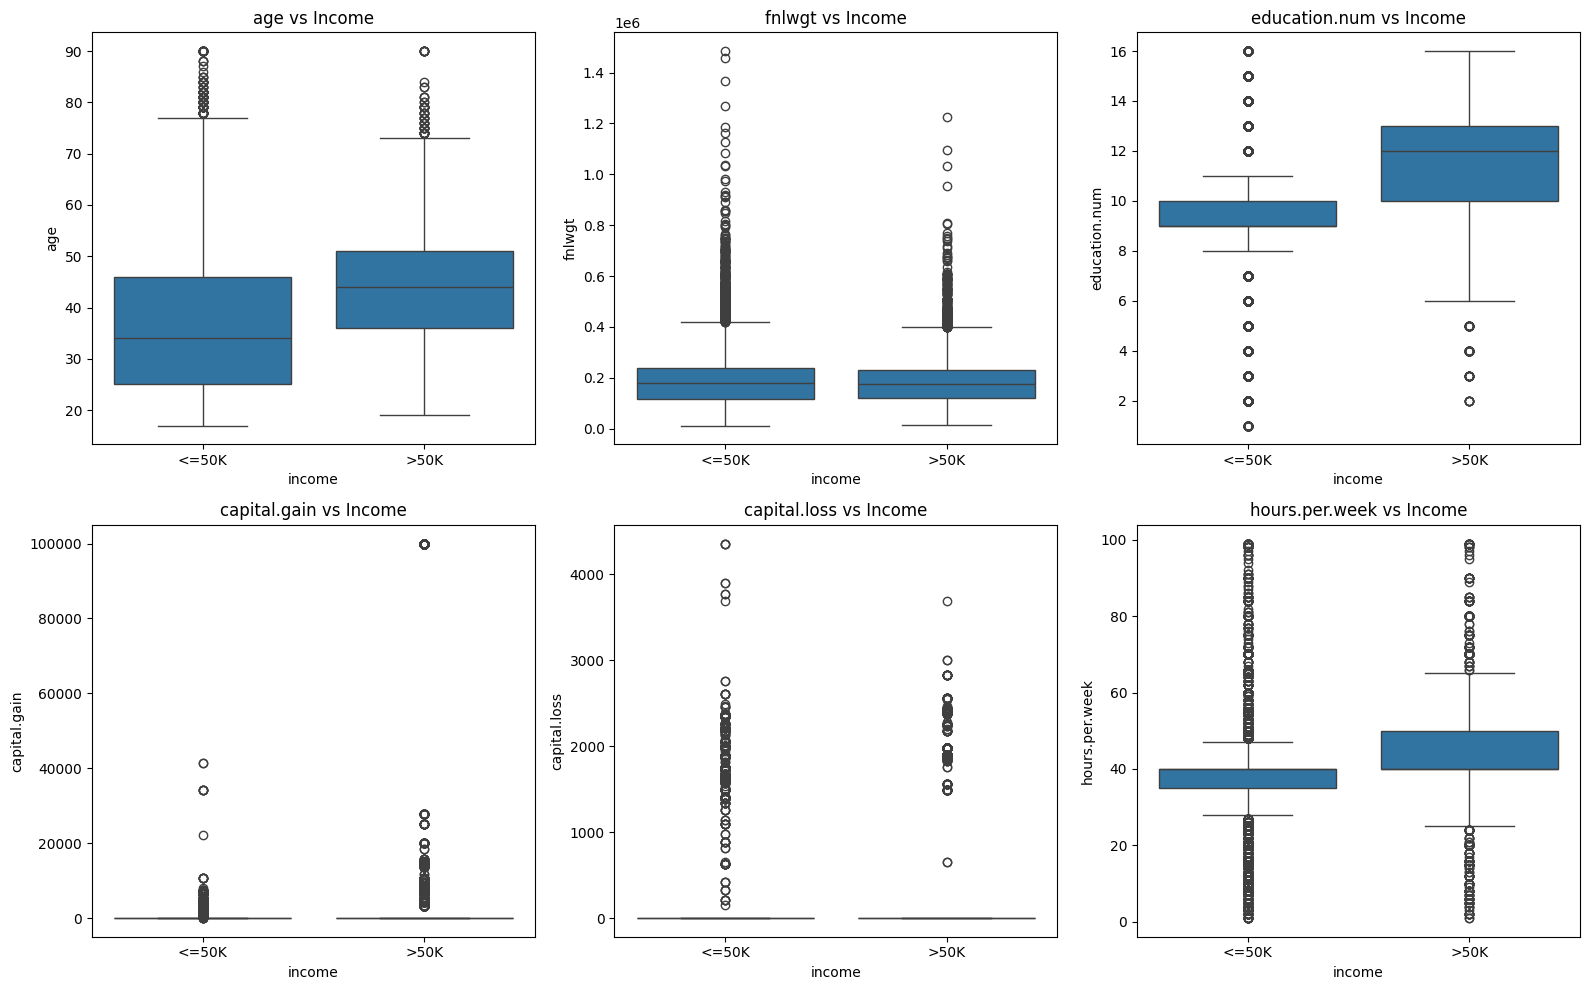

In [65]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for col, ax in zip(numerical_cols, axes.flatten()):
    sns.boxplot(data=df, x='income', y=col, ax=ax)
    ax.set_title(f'{col} vs Income')

plt.tight_layout()
plt.show()

In [66]:
df[(df['age'] > 75) & (df['income'] == '<=50K')]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,age_group
0,90,Private,77053,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,4356,40,United-States,<=50K,Senior
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K,Senior
199,90,Private,51744,HS-grad,9,Never-married,Other-service,Not-in-family,Black,Male,0,2206,40,United-States,<=50K,Senior
534,77,Self-emp-not-inc,71676,Some-college,10,Widowed,Adm-clerical,Not-in-family,White,Female,0,1944,1,United-States,<=50K,Senior
992,80,Private,87518,Some-college,10,Never-married,Prof-specialty,Not-in-family,White,Male,0,1816,60,United-States,<=50K,Senior
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31939,82,Self-emp-not-inc,71438,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,20,United-States,<=50K,Senior
32305,90,Private,313749,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,25,United-States,<=50K,Senior
32468,85,Private,98611,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,3,Poland,<=50K,Senior
32500,82,Private,403910,HS-grad,9,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,3,United-States,<=50K,Senior


In [67]:
df[(df['age'] > 75) & (df['income'] == '>50K')]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,age_group
116,78,Self-emp-inc,188044,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,2392,40,United-States,>50K,Senior
118,83,Self-emp-inc,153183,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,2392,55,United-States,>50K,Senior
128,81,Private,177408,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,2377,26,United-States,>50K,Senior
1546,78,Self-emp-not-inc,316261,Bachelors,13,Never-married,Exec-managerial,Not-in-family,White,Male,99999,0,20,United-States,>50K,Senior
1739,90,Local-gov,227796,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,20051,0,60,United-States,>50K,Senior
1740,79,Private,120707,Doctorate,16,Married-civ-spouse,Prof-specialty,Husband,White,Male,20051,0,35,El-Salvador,>50K,Senior
1742,90,Private,87372,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,20051,0,72,United-States,>50K,Senior
1758,77,Self-emp-inc,84979,Doctorate,16,Married-civ-spouse,Farming-fishing,Husband,White,Male,20051,0,40,United-States,>50K,Senior
1760,76,Private,199949,Bachelors,13,Married-civ-spouse,Adm-clerical,Husband,White,Male,20051,0,50,United-States,>50K,Senior
1761,83,Self-emp-inc,240150,10th,6,Married-civ-spouse,Farming-fishing,Husband,White,Male,20051,0,50,United-States,>50K,Senior


In [68]:
df[(df['education.num']<5)& (df['income'] == '>50K') ]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,age_group
479,50,Self-emp-inc,201689,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,White,Male,0,1977,63,United-States,>50K,Middle_Age
597,24,Self-emp-not-inc,322931,7th-8th,4,Married-civ-spouse,Transport-moving,Husband,White,Male,0,1902,40,United-States,>50K,Young
742,40,Local-gov,289403,7th-8th,4,Married-civ-spouse,Craft-repair,Husband,Black,Male,0,1887,40,United-States,>50K,Adult
774,56,Self-emp-not-inc,162130,5th-6th,3,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,1887,67,United-States,>50K,Middle_Age
2541,53,Self-emp-not-inc,145419,1st-4th,2,Married-civ-spouse,Exec-managerial,Husband,White,Male,7688,0,67,Italy,>50K,Middle_Age
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29619,61,Self-emp-not-inc,196773,7th-8th,4,Married-civ-spouse,Sales,Husband,White,Male,0,0,30,United-States,>50K,Senior
29678,48,Private,440706,7th-8th,4,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K,Middle_Age
29748,60,Private,532845,1st-4th,2,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,40,Mexico,>50K,Middle_Age
29821,60,Private,188650,5th-6th,3,Married-civ-spouse,Sales,Husband,White,Male,0,0,40,United-States,>50K,Middle_Age


In [69]:
df[(df['capital.gain'] > 80000) & (df['income'] == '>50K')]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,age_group
1519,54,Self-emp-inc,166459,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,99999,0,60,United-States,>50K,Middle_Age
1520,52,Private,152234,HS-grad,9,Married-civ-spouse,Exec-managerial,Husband,Asian-Pac-Islander,Male,99999,0,40,Japan,>50K,Middle_Age
1521,53,Self-emp-inc,263925,HS-grad,9,Married-civ-spouse,Sales,Husband,White,Male,99999,0,40,United-States,>50K,Middle_Age
1522,52,Private,118025,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,99999,0,50,United-States,>50K,Middle_Age
1523,46,Private,370119,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,99999,0,60,United-States,>50K,Middle_Age
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1673,47,Private,155664,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,99999,0,55,United-States,>50K,Middle_Age
1674,43,Self-emp-inc,62026,Prof-school,15,Married-civ-spouse,Exec-managerial,Husband,White,Male,99999,0,40,United-States,>50K,Middle_Age
1675,66,Private,115498,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,99999,0,55,United-States,>50K,Senior
1676,47,Private,294913,Prof-school,15,Married-civ-spouse,Exec-managerial,Husband,White,Male,99999,0,40,United-States,>50K,Middle_Age


In [70]:
df[(df['hours.per.week'] > 80) ]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income,age_group
29,38,Private,175360,10th,6,Never-married,Prof-specialty,Not-in-family,White,Male,0,2559,90,United-States,>50K,Adult
92,39,Private,348521,Some-college,10,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,2415,99,United-States,>50K,Adult
98,39,Private,237713,Prof-school,15,Married-civ-spouse,Sales,Husband,White,Male,0,2415,99,United-States,>50K,Adult
106,38,Private,187870,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,2415,90,United-States,>50K,Adult
165,33,Private,288825,HS-grad,9,Divorced,Craft-repair,Not-in-family,White,Male,0,2258,84,United-States,<=50K,Adult
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32409,55,Private,199763,HS-grad,9,Separated,Protective-serv,Not-in-family,White,Male,0,0,81,United-States,<=50K,Middle_Age
32417,42,Private,288154,Some-college,10,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,89,United-States,>50K,Middle_Age
32476,58,Self-emp-inc,181974,Doctorate,16,Never-married,Prof-specialty,Not-in-family,White,Female,0,0,99,United-States,<=50K,Middle_Age
32482,35,Private,30673,12th,8,Married-civ-spouse,Craft-repair,Husband,White,Male,0,0,84,United-States,<=50K,Adult


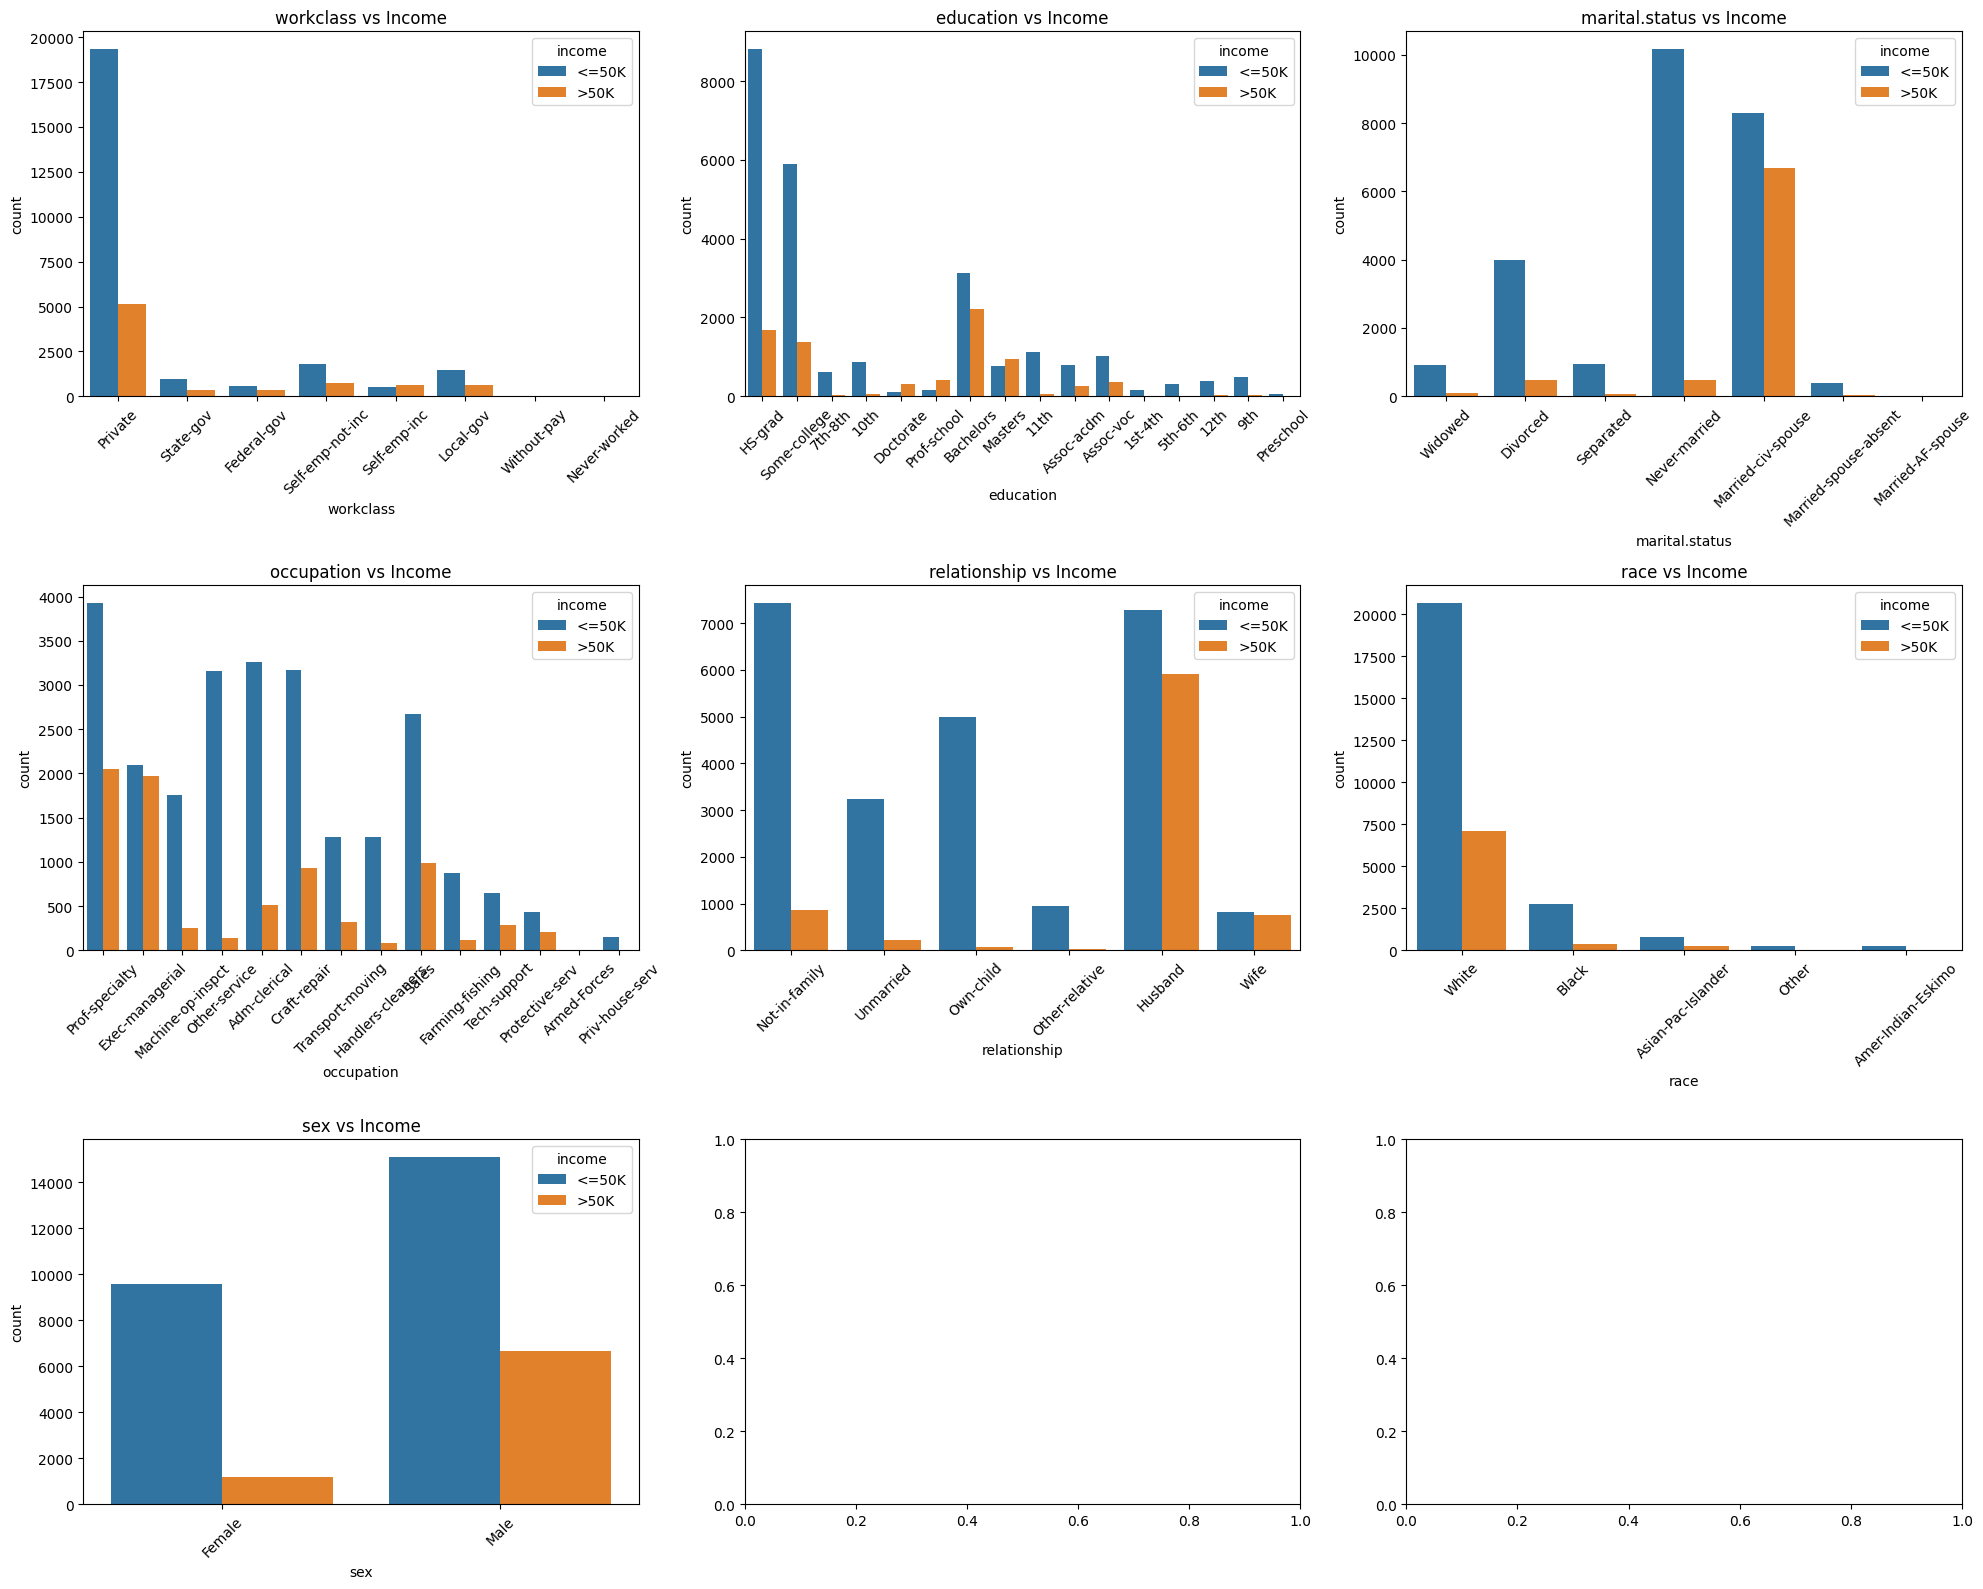

In [71]:
categorical_cols = [
    'workclass', 'education', 'marital.status',
    'occupation', 'relationship', 'race', 'sex'
]

fig, axes = plt.subplots(3, 3, figsize=(20, 16))

for col, ax in zip(categorical_cols, axes.flatten()):
    sns.countplot(data=df, x=col, hue='income', ax=ax)
    ax.set_title(f'{col} vs Income')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

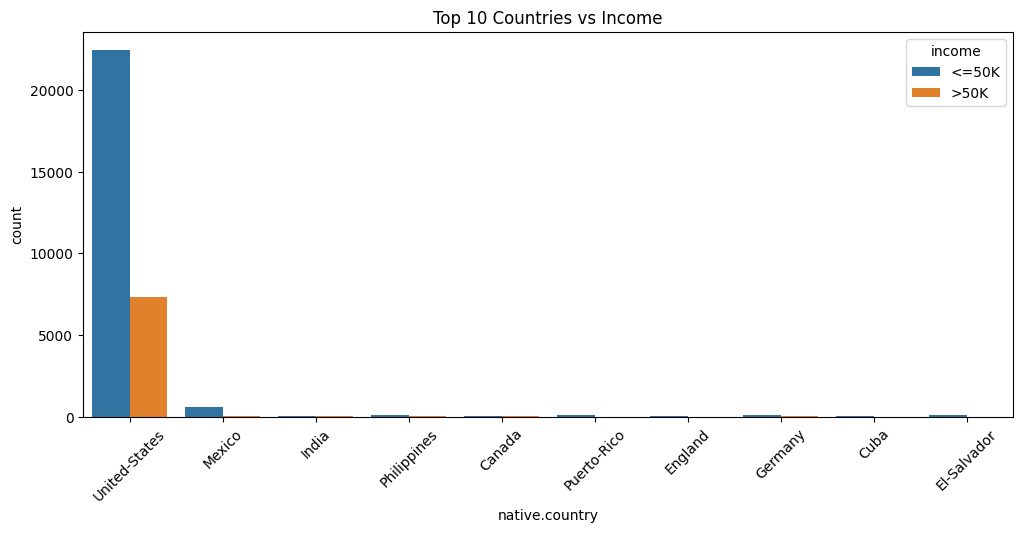

In [72]:
top_countries = df['native.country'].value_counts().head(10).index

plt.figure(figsize=(12, 5))
sns.countplot(
    data=df[df['native.country'].isin(top_countries)],
    x='native.country',
    hue='income'
)
plt.xticks(rotation=45)
plt.title('Top 10 Countries vs Income')
plt.show()

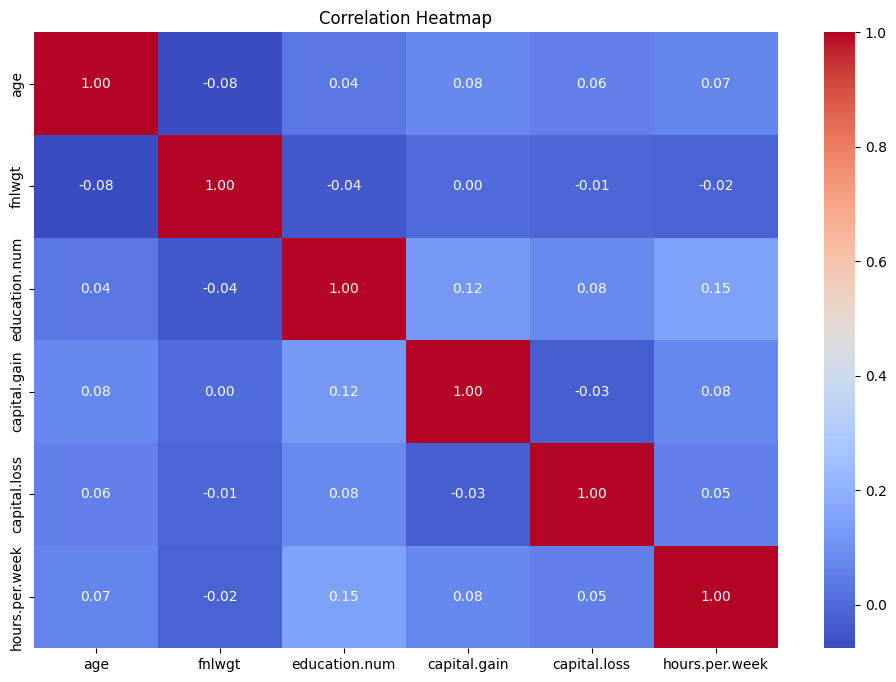

In [73]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df[numerical_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

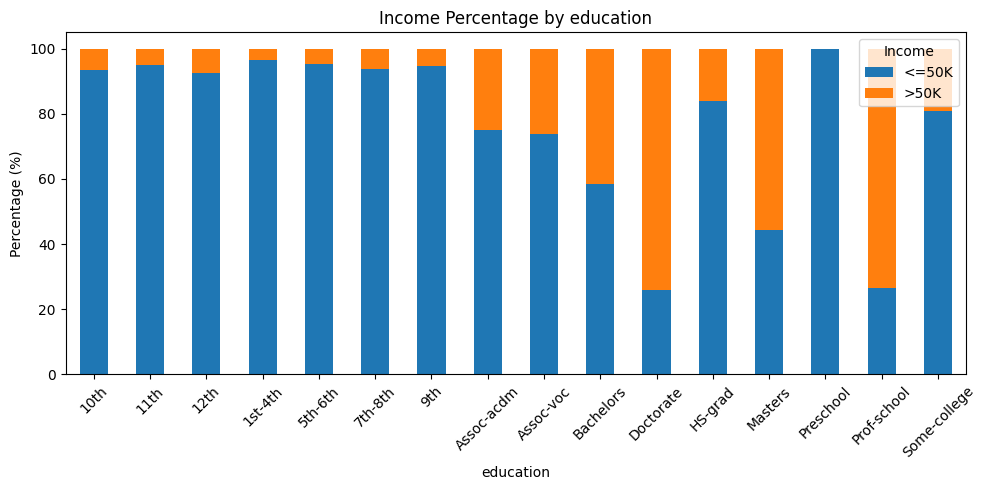

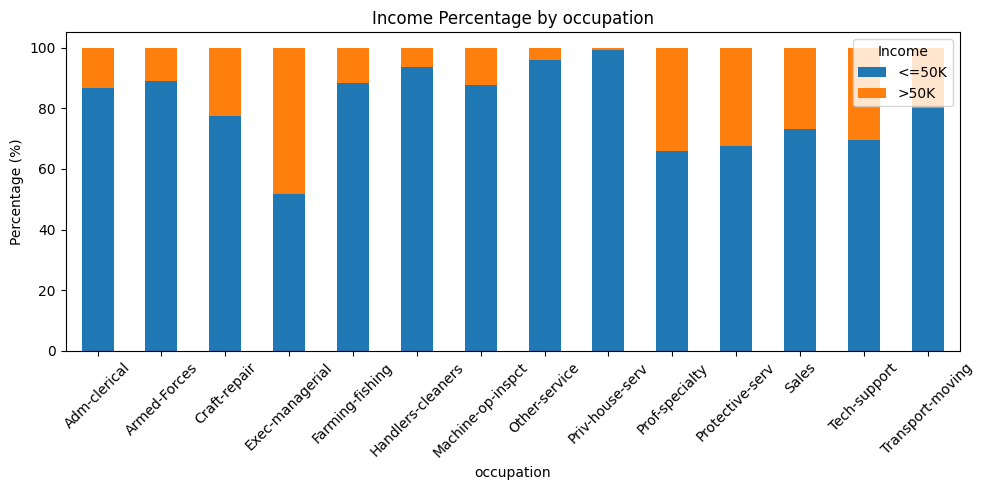

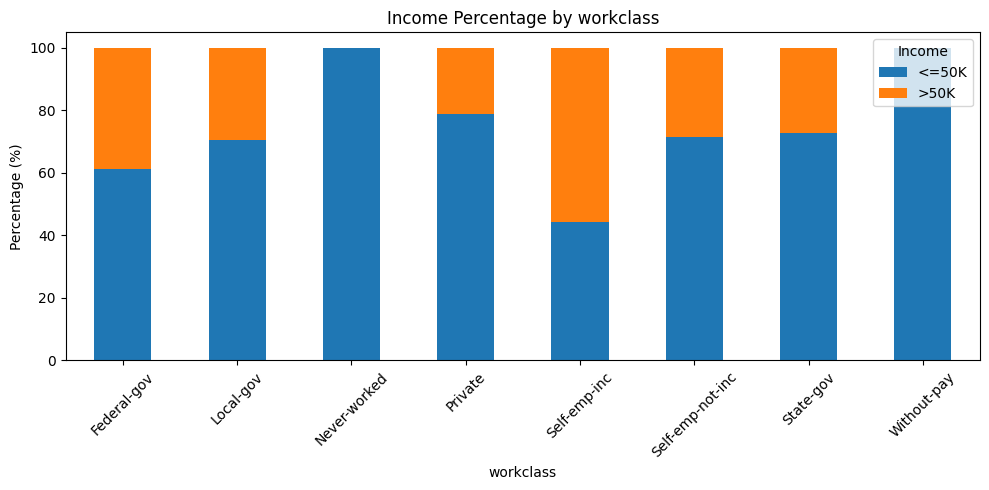

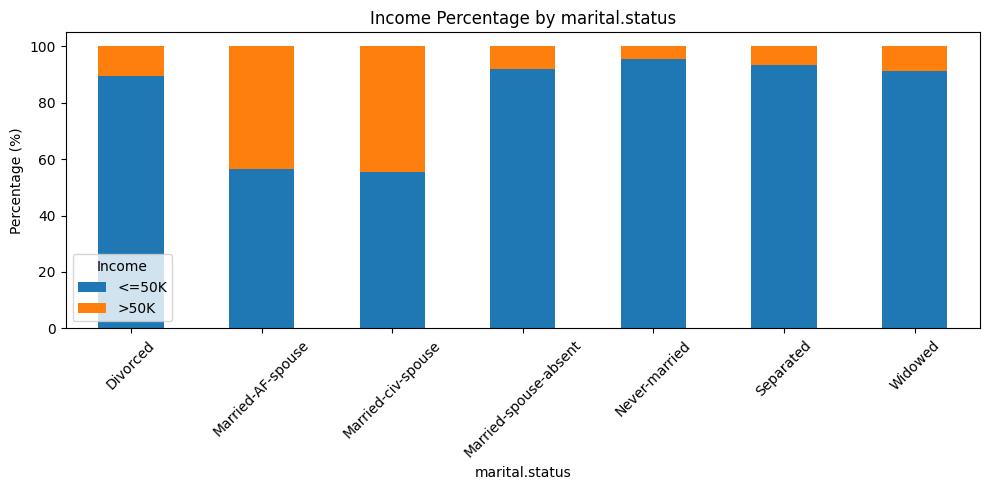

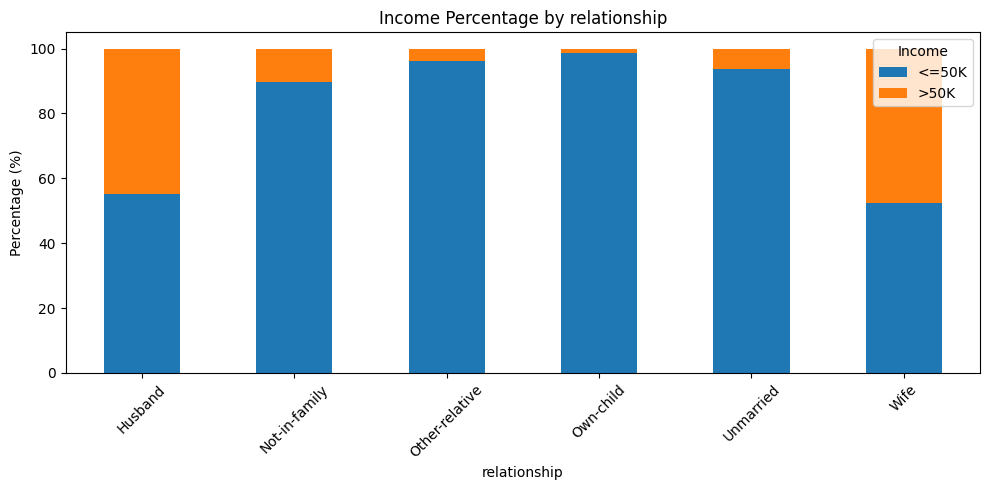

In [74]:
for col in ['education', 'occupation', 'workclass',
            'marital.status', 'relationship']:

    income_pct = pd.crosstab(
        df[col],
        df['income'],
        normalize='index'
    ) * 100

    income_pct.plot(
        kind='bar',
        stacked=True,
        figsize=(10, 5)
    )

    plt.title(f'Income Percentage by {col}')
    plt.ylabel('Percentage (%)')
    plt.xticks(rotation=45)
    plt.legend(title='Income')
    plt.tight_layout()
    plt.show()

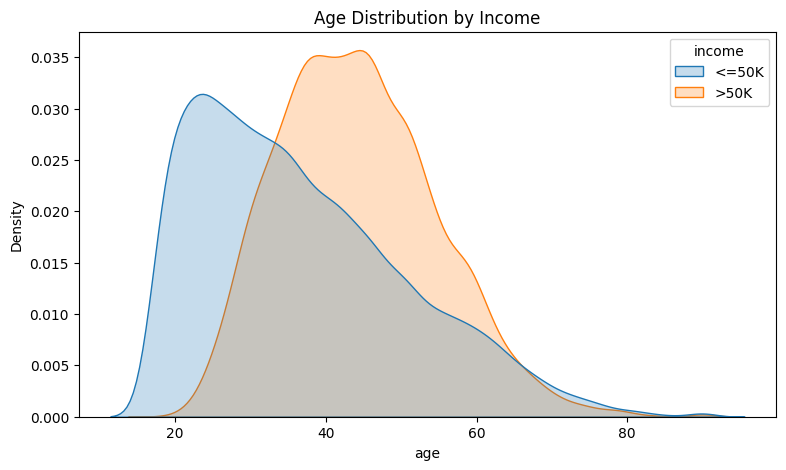

In [75]:
plt.figure(figsize=(9, 5))

sns.kdeplot(
    data=df,
    x='age',
    hue='income',
    fill=True,
    common_norm=False
)

plt.title('Age Distribution by Income')
plt.show()

In [76]:
X=df.drop(['income','age_group'],axis=1)
y=df['income']


In [77]:
y = y.str.strip().map({
    '<=50K': 0,
    '>50K': 1
})

In [78]:
# Split into Input and Output Elements
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                   test_size= 0.20, random_state=100, stratify=y)

In [79]:
numerical_cols = X_train.select_dtypes(include=np.number).columns

categorical_cols = X_train.select_dtypes(include='object').columns

In [80]:
X_train = pd.get_dummies(
    X_train,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

In [81]:
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

In [82]:

scaler = StandardScaler()

X_train[numerical_cols] = scaler.fit_transform(
    X_train[numerical_cols]
)

X_test[numerical_cols] = scaler.transform(
    X_test[numerical_cols]
)

In [83]:
print(X_train.shape)
print(X_test.shape)

print(X_train.head())
print(y_train.value_counts())

(26029, 97)
(6508, 97)
            age    fnlwgt  education.num  capital.gain  capital.loss  \
23587 -1.434818 -1.382958      -0.425334     -0.145558     -0.218009   
29440  1.424792  0.254301      -1.979107     -0.145558     -0.218009   
29022  0.251619 -0.324955      -0.425334     -0.145558     -0.218009   
27273  0.324942  0.207057      -0.425334     -0.145558     -0.218009   
13007 -0.554938 -0.422264       1.128439     -0.145558     -0.218009   

       hours.per.week  workclass_Local-gov  workclass_Never-worked  \
23587       -2.472767                    0                       0   
29440       -0.037720                    0                       0   
29022       -1.255244                    0                       0   
27273       -1.336412                    0                       0   
13007        1.585645                    0                       0   

       workclass_Private  workclass_Self-emp-inc  ...  \
23587                  0                       0  ...   
29440    

In [84]:
models = {

    # Linear
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=1),

    # Distance-based
    "KNN": KNeighborsClassifier(n_neighbors=5),

    # SVM
    "SVC": SVC(probability=True, random_state=1),

    # Tree
    "Decision Tree": DecisionTreeClassifier(random_state=1),

    # Naive Bayes
    "Naive Bayes": GaussianNB(),

    # Bagging Based
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=1),

    # Boosting
    "AdaBoost": AdaBoostClassifier(random_state=1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=1),

    # External Boosting Libraries
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=1, use_label_encoder=False),
    "CatBoost": CatBoostClassifier(verbose=0, random_state=1),
    "LightGBM": LGBMClassifier(random_state=1)
}

  0%|          | 0/13 [00:00<?, ?it/s]


Confusion Matrix:
 [[4609  331]
 [ 635  933]]


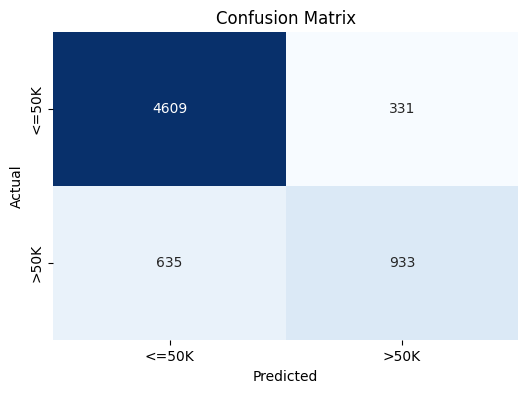


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      4940
        >50K       0.74      0.60      0.66      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.76      0.78      6508
weighted avg       0.84      0.85      0.85      6508

ROC-AUC: 0.9114884997521275


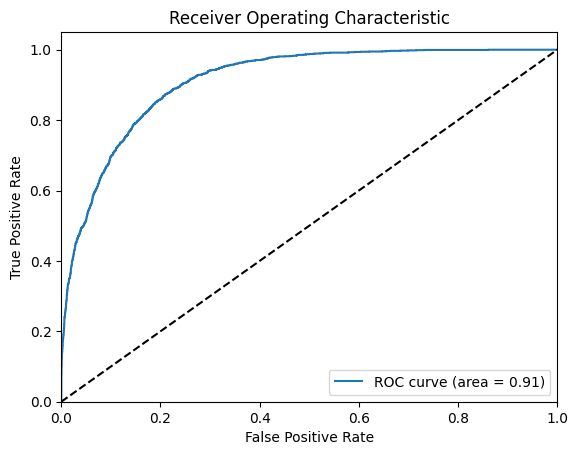

PR AUC: 0.7723670666944394


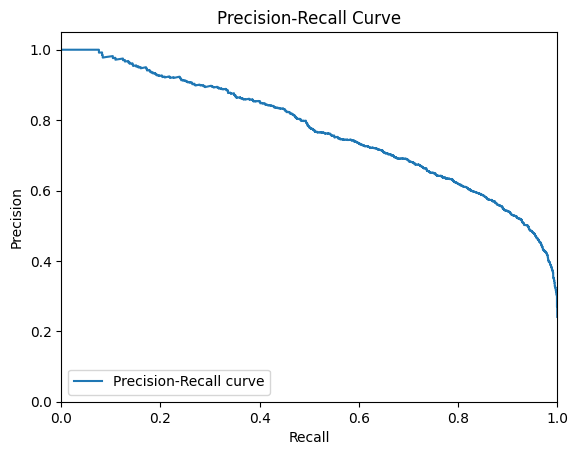

  8%|▊         | 1/13 [00:02<00:29,  2.45s/it]


Confusion Matrix:
 [[4504  436]
 [ 607  961]]


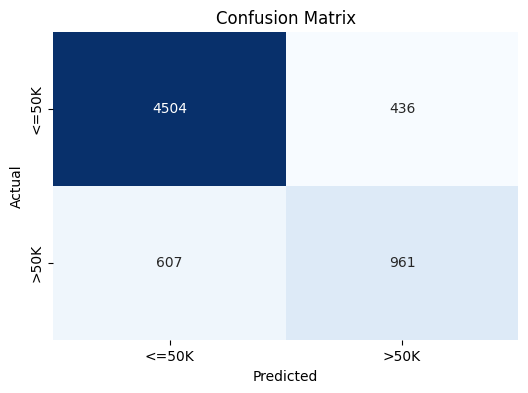


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.90      4940
        >50K       0.69      0.61      0.65      1568

    accuracy                           0.84      6508
   macro avg       0.78      0.76      0.77      6508
weighted avg       0.83      0.84      0.84      6508

ROC-AUC: 0.8689042102164752


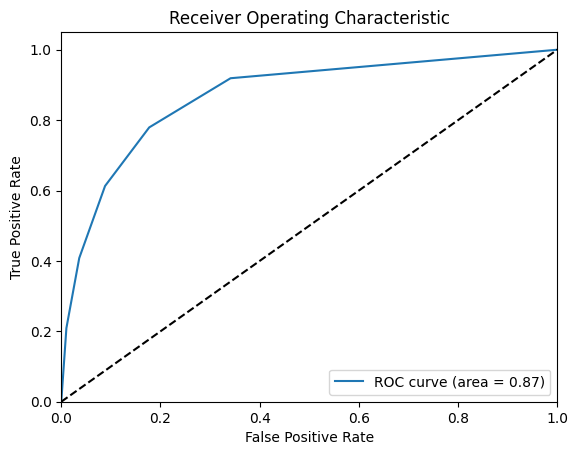

PR AUC: 0.6581826116337415


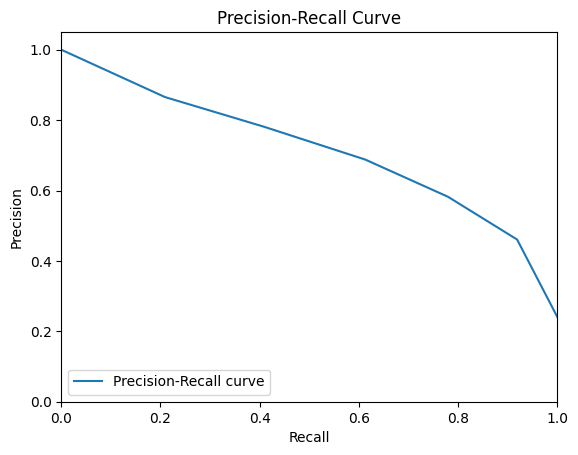

 15%|█▌        | 2/13 [00:32<03:25, 18.69s/it]


Confusion Matrix:
 [[4671  269]
 [ 663  905]]


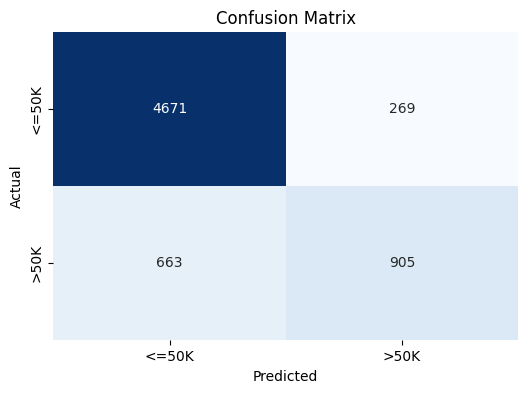


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.91      4940
        >50K       0.77      0.58      0.66      1568

    accuracy                           0.86      6508
   macro avg       0.82      0.76      0.78      6508
weighted avg       0.85      0.86      0.85      6508

ROC-AUC: 0.9047974933900687


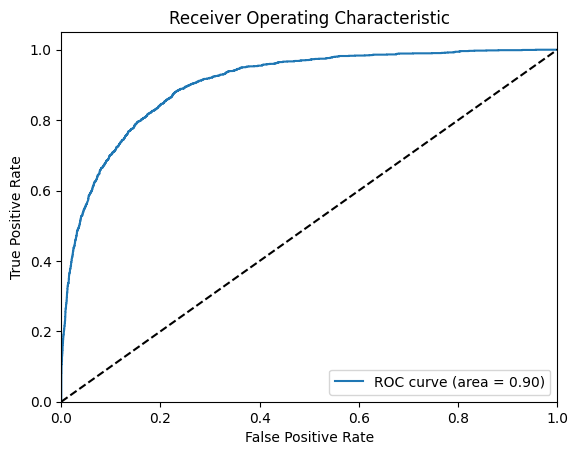

PR AUC: 0.7729715324405261


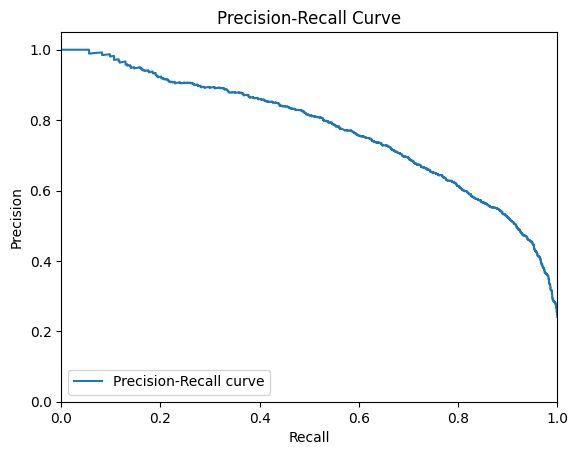

 23%|██▎       | 3/13 [06:22<28:18, 169.80s/it]


Confusion Matrix:
 [[4345  595]
 [ 590  978]]


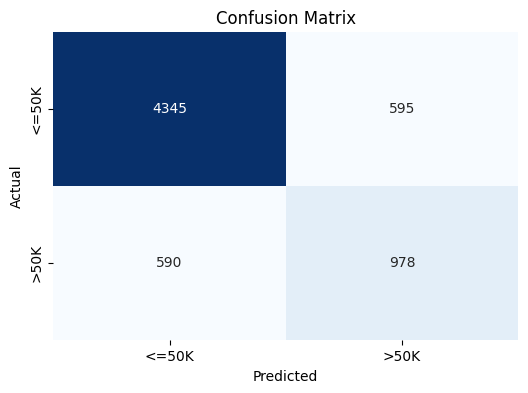


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88      4940
        >50K       0.62      0.62      0.62      1568

    accuracy                           0.82      6508
   macro avg       0.75      0.75      0.75      6508
weighted avg       0.82      0.82      0.82      6508

ROC-AUC: 0.7516395728331817


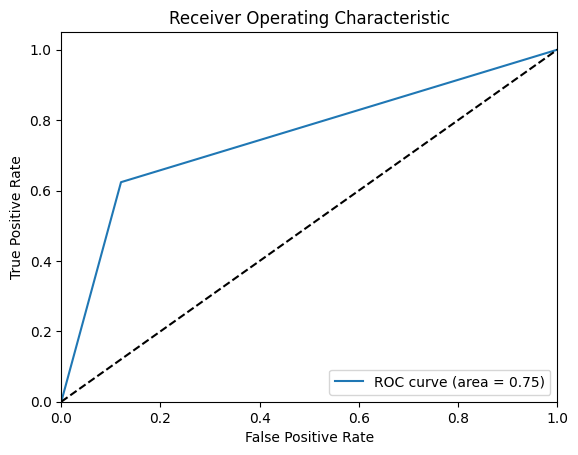

PR AUC: 0.4784532980329961


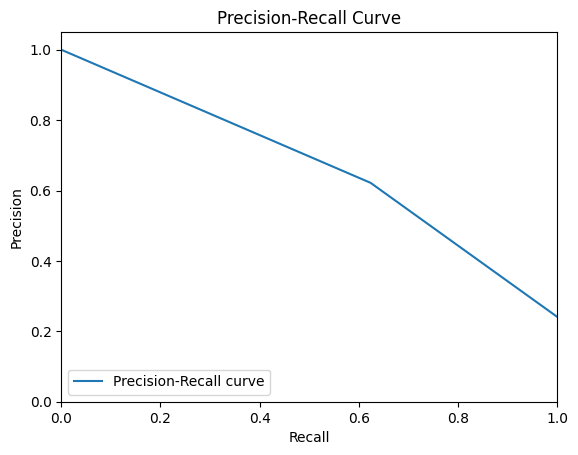

 31%|███       | 4/13 [06:23<15:29, 103.24s/it]


Confusion Matrix:
 [[1494 3446]
 [  42 1526]]


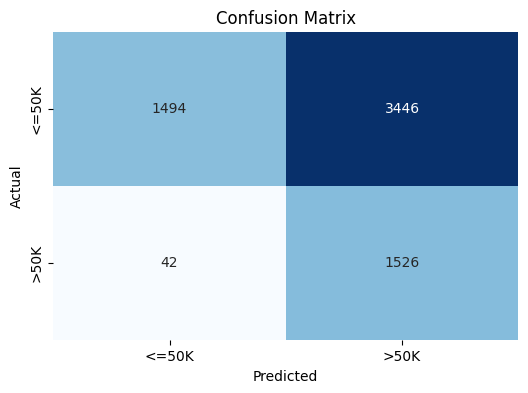


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.97      0.30      0.46      4940
        >50K       0.31      0.97      0.47      1568

    accuracy                           0.46      6508
   macro avg       0.64      0.64      0.46      6508
weighted avg       0.81      0.46      0.46      6508

ROC-AUC: 0.7086717910848548


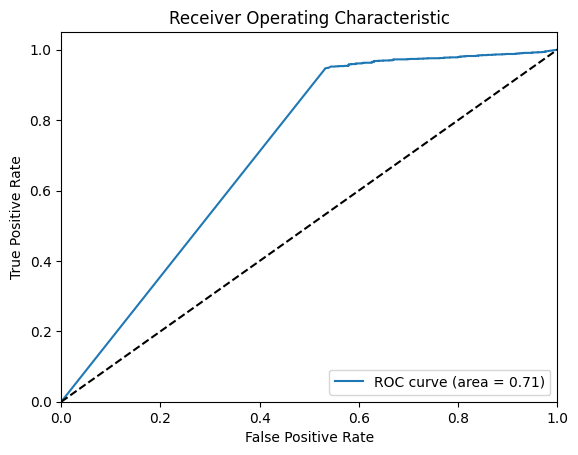

PR AUC: 0.3576521212654499


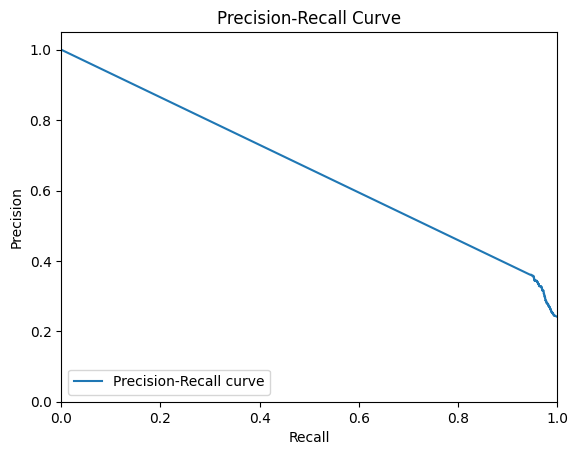

 38%|███▊      | 5/13 [06:24<08:50, 66.30s/it] 


Confusion Matrix:
 [[4594  346]
 [ 608  960]]


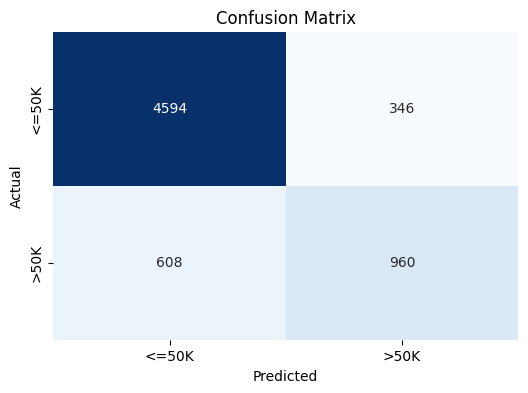


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      4940
        >50K       0.74      0.61      0.67      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.77      0.79      6508
weighted avg       0.85      0.85      0.85      6508

ROC-AUC: 0.9059374483599107


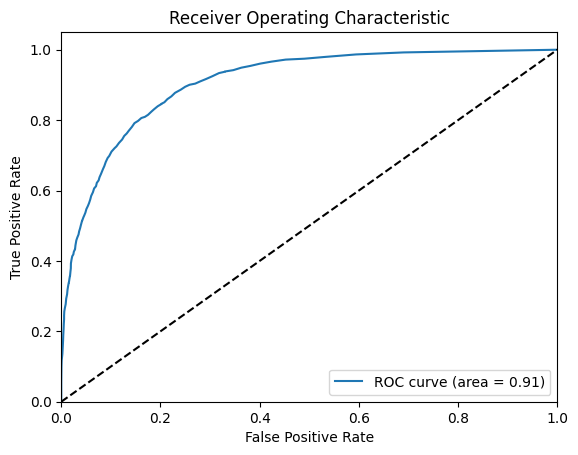

PR AUC: 0.769569406212359


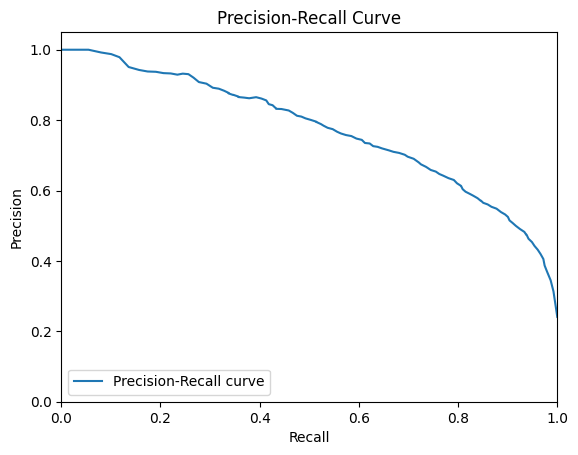

 46%|████▌     | 6/13 [06:30<05:21, 45.91s/it]


Confusion Matrix:
 [[4513  427]
 [ 628  940]]


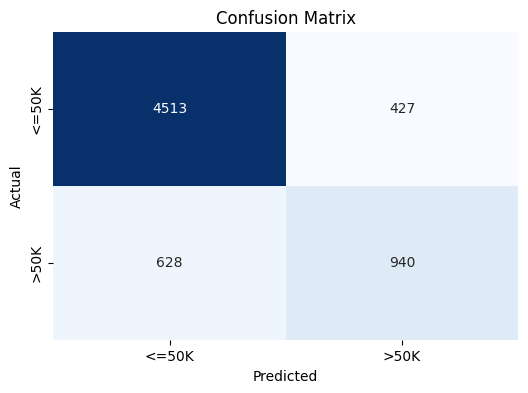


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.91      0.90      4940
        >50K       0.69      0.60      0.64      1568

    accuracy                           0.84      6508
   macro avg       0.78      0.76      0.77      6508
weighted avg       0.83      0.84      0.83      6508

ROC-AUC: 0.8815120089027513


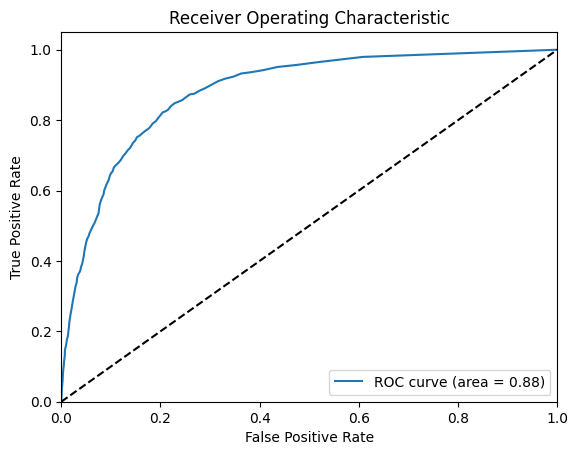

PR AUC: 0.6911112590882482


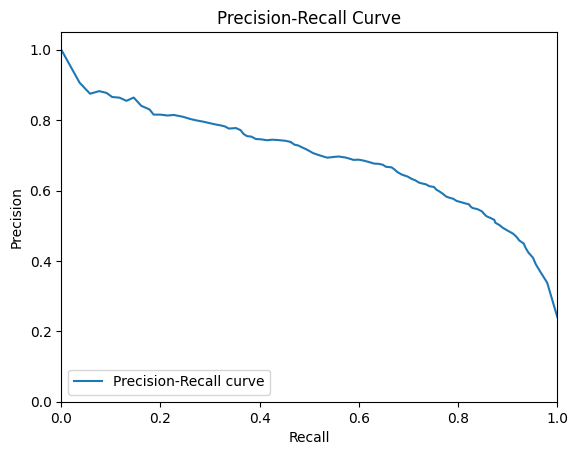

 54%|█████▍    | 7/13 [06:39<03:22, 33.78s/it]


Confusion Matrix:
 [[4647  293]
 [ 671  897]]


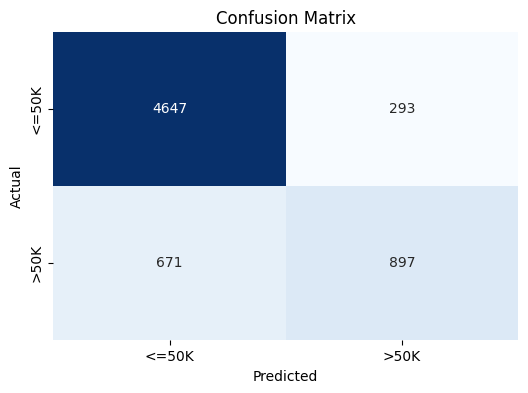


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.87      0.94      0.91      4940
        >50K       0.75      0.57      0.65      1568

    accuracy                           0.85      6508
   macro avg       0.81      0.76      0.78      6508
weighted avg       0.84      0.85      0.84      6508

ROC-AUC: 0.9098058719945468


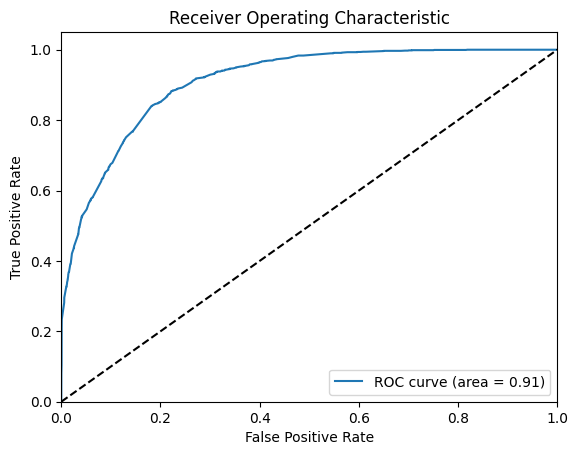

PR AUC: 0.7775595569545403


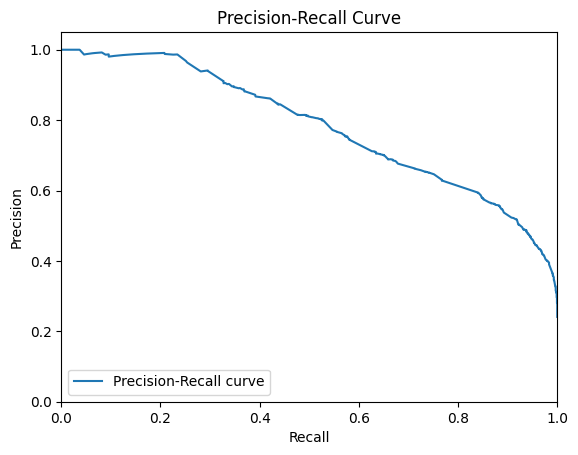

 62%|██████▏   | 8/13 [06:41<01:59, 23.83s/it]


Confusion Matrix:
 [[4696  244]
 [ 626  942]]


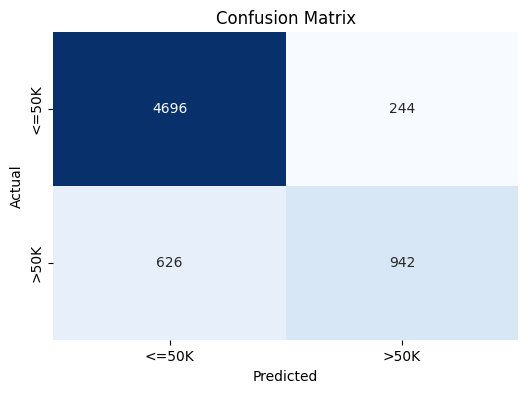


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.92      4940
        >50K       0.79      0.60      0.68      1568

    accuracy                           0.87      6508
   macro avg       0.84      0.78      0.80      6508
weighted avg       0.86      0.87      0.86      6508

ROC-AUC: 0.9257079856233993


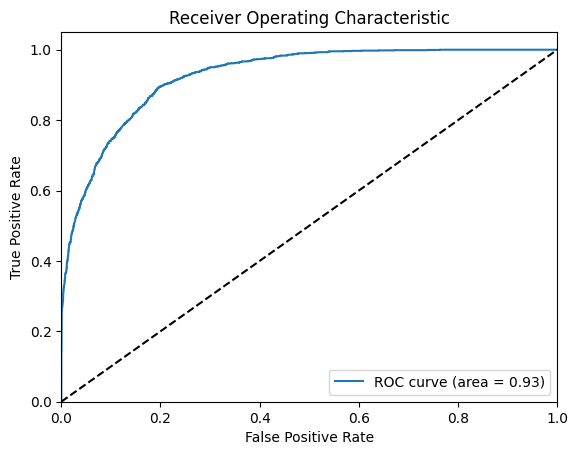

PR AUC: 0.8184544527707229


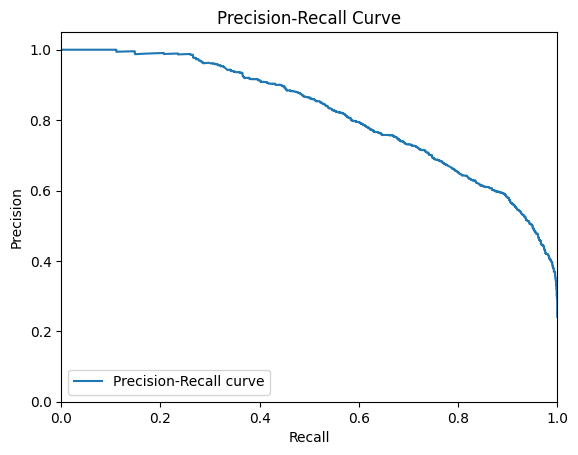

 69%|██████▉   | 9/13 [06:48<01:14, 18.50s/it]


Confusion Matrix:
 [[4656  284]
 [ 541 1027]]


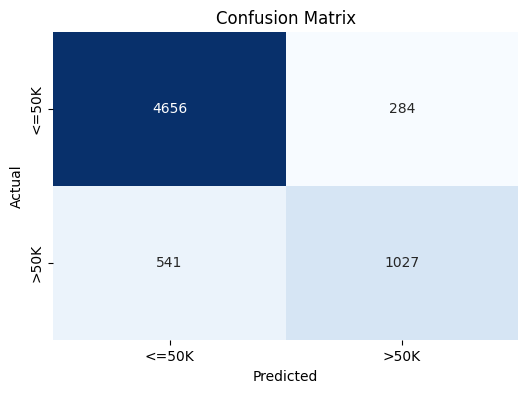


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.90      0.94      0.92      4940
        >50K       0.78      0.65      0.71      1568

    accuracy                           0.87      6508
   macro avg       0.84      0.80      0.82      6508
weighted avg       0.87      0.87      0.87      6508

ROC-AUC: 0.9305930089647195


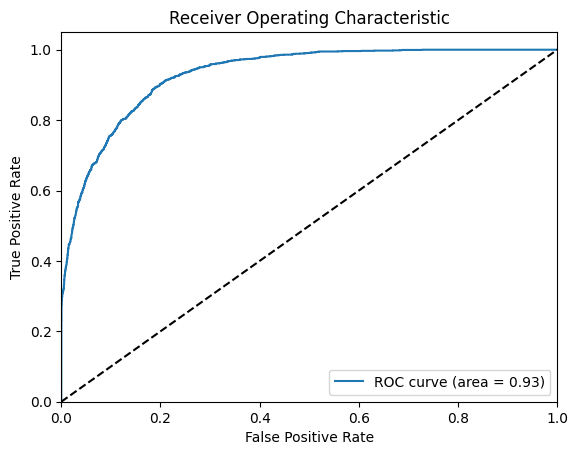

PR AUC: 0.8294200093198141


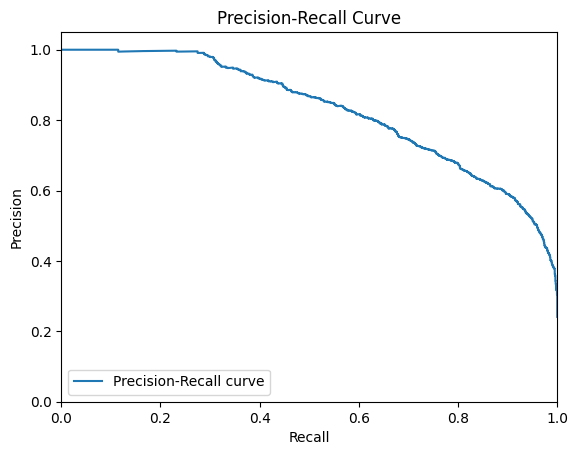

 77%|███████▋  | 10/13 [06:52<00:41, 13.99s/it]/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [11:51:35] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4643  297]
 [ 535 1033]]


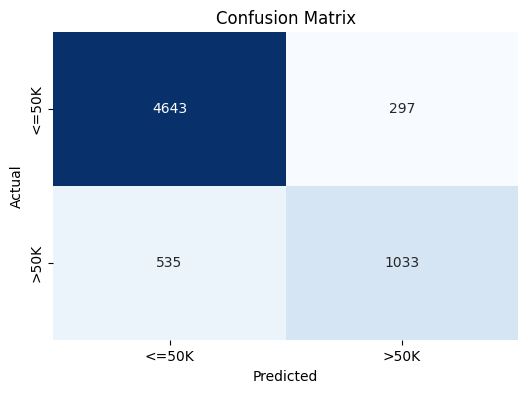


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.90      0.94      0.92      4940
        >50K       0.78      0.66      0.71      1568

    accuracy                           0.87      6508
   macro avg       0.84      0.80      0.82      6508
weighted avg       0.87      0.87      0.87      6508

ROC-AUC: 0.9311530457324632


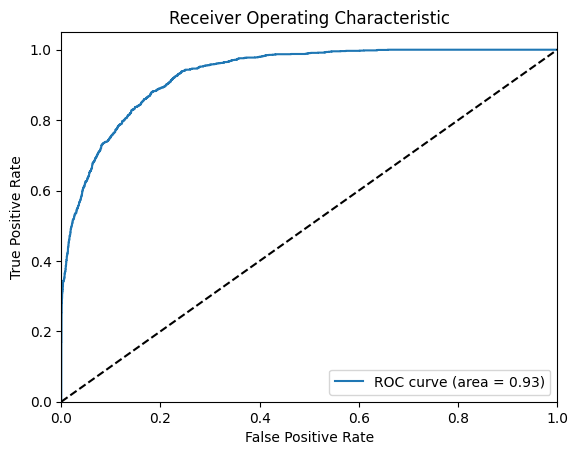

PR AUC: 0.8314014977054602


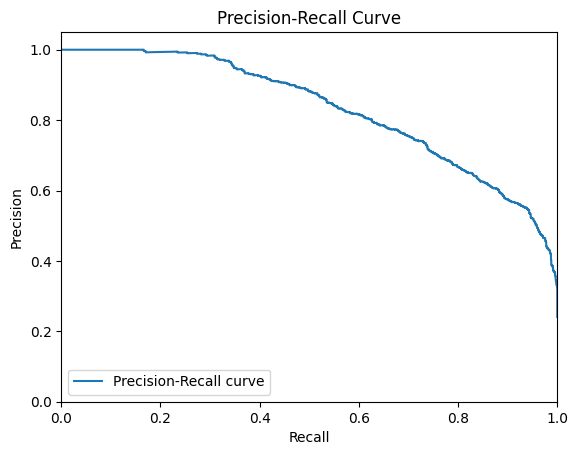

 85%|████████▍ | 11/13 [06:53<00:20, 10.15s/it]


Confusion Matrix:
 [[4661  279]
 [ 551 1017]]


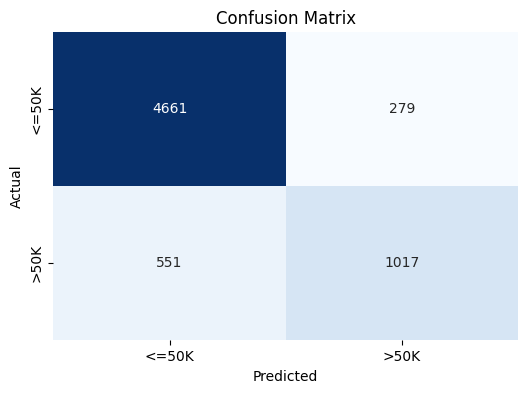


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.92      4940
        >50K       0.78      0.65      0.71      1568

    accuracy                           0.87      6508
   macro avg       0.84      0.80      0.81      6508
weighted avg       0.87      0.87      0.87      6508

ROC-AUC: 0.9330184794059325


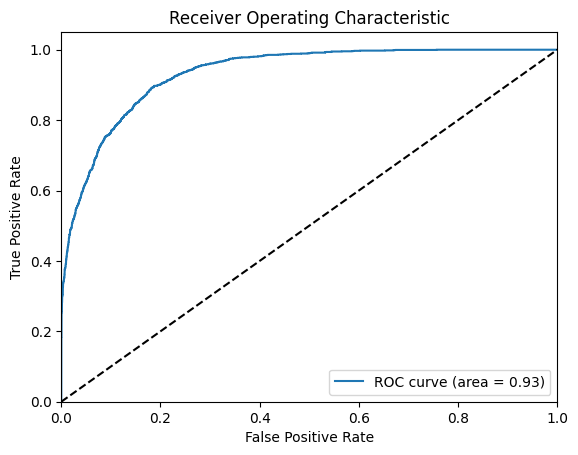

PR AUC: 0.8344133362695082


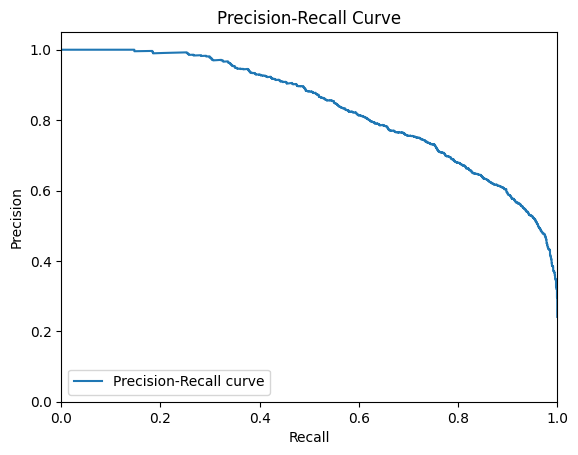

 92%|█████████▏| 12/13 [07:04<00:10, 10.32s/it]

[LightGBM] [Info] Number of positive: 6271, number of negative: 19758
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.019641 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 747
[LightGBM] [Info] Number of data points in the train set: 26029, number of used features: 83
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.240924 -> initscore=-1.147623
[LightGBM] [Info] Start training from score -1.147623

Confusion Matrix:
 [[4654  286]
 [ 558 1010]]


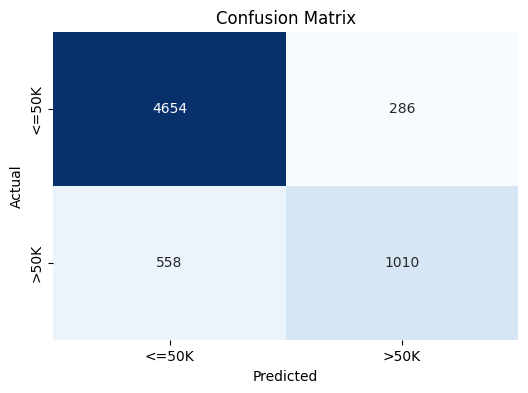


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.92      4940
        >50K       0.78      0.64      0.71      1568

    accuracy                           0.87      6508
   macro avg       0.84      0.79      0.81      6508
weighted avg       0.87      0.87      0.87      6508

ROC-AUC: 0.9312467724944229


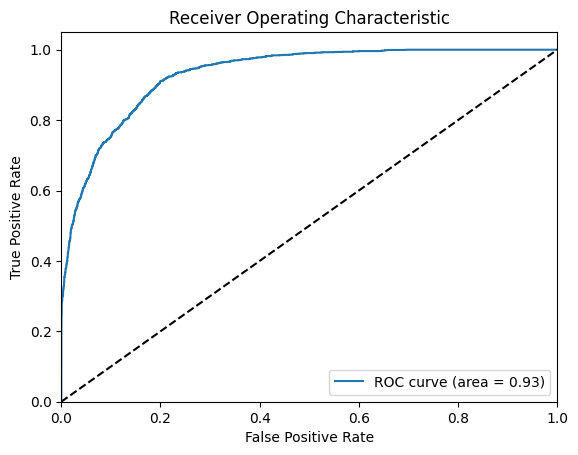

PR AUC: 0.8308331805327748


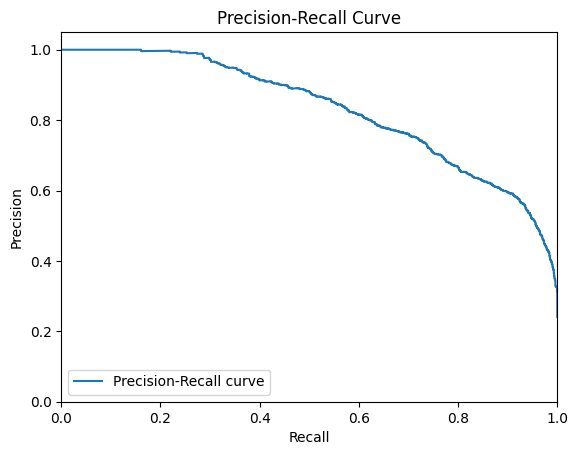

100%|██████████| 13/13 [07:06<00:00, 32.78s/it]


In [85]:
results = {}

for name, model in tqdm(models.items()):
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred  = model.predict(X_test)

    cm = confusion_matrix(y_test, test_pred)
    print("\nConfusion Matrix:\n", cm)

    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
                xticklabels=['<=50K', '>50K'],
                yticklabels=['<=50K', '>50K'])
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.title('Confusion Matrix')
    plt.show()

    # Full classification report
    print("\nClassification Report:\n")
    print(classification_report(
        y_test, test_pred,
        target_names=['<=50K', '>50K'],
        zero_division=0
    ))

    y_pred_prob = model.predict_proba(X_test)[:, 1]
    roc_auc = roc_auc_score(y_test, y_pred_prob)
    print("ROC-AUC:", roc_auc)

    # ROC curve
    fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

    pr_auc = average_precision_score(y_test, y_pred_prob)
    print("PR AUC:", pr_auc)

    precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
    plt.figure()
    plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.show()

    results[name] = {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Test Accuracy": accuracy_score(y_test, test_pred),
        "Train Precision": precision_score(y_train, train_pred, zero_division=0),
        "Test Precision": precision_score(y_test, test_pred, zero_division=0),
        "Train Recall": recall_score(y_train, train_pred, zero_division=0),
        "Test Recall": recall_score(y_test, test_pred, zero_division=0),
        "Train F1 Score": f1_score(y_train, train_pred, zero_division=0),
        "Test F1 Score": f1_score(y_test, test_pred, zero_division=0),
        "Train Balanced Accuracy": balanced_accuracy_score(y_train, train_pred),
        "Test Balanced Accuracy": balanced_accuracy_score(y_test, test_pred),
        "ROC-AUC": roc_auc,
        "PR AUC": pr_auc
    }

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [11:51:54] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



Confusion Matrix:
 [[4326  614]
 [ 335 1233]]


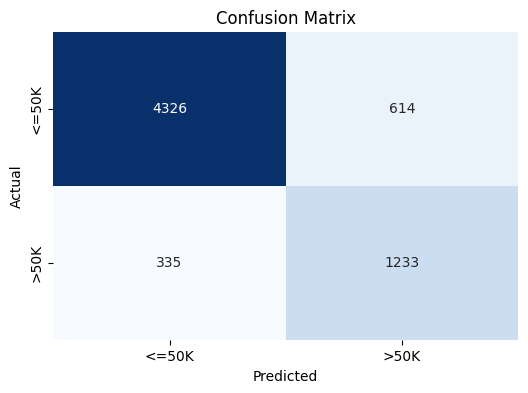


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.93      0.88      0.90      4940
        >50K       0.67      0.79      0.72      1568

    accuracy                           0.85      6508
   macro avg       0.80      0.83      0.81      6508
weighted avg       0.87      0.85      0.86      6508

ROC-AUC: 0.9208597558456579


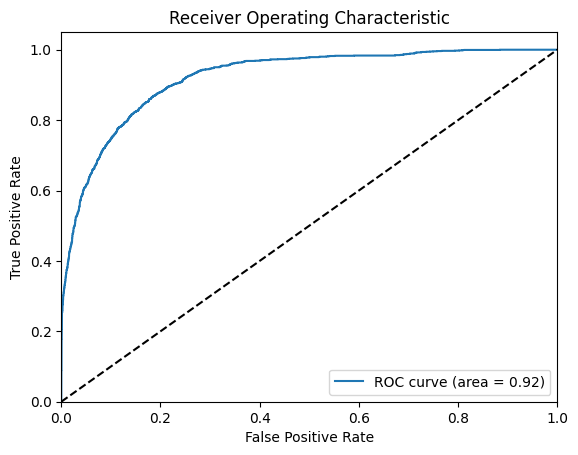

PR AUC: 0.8146454404887472


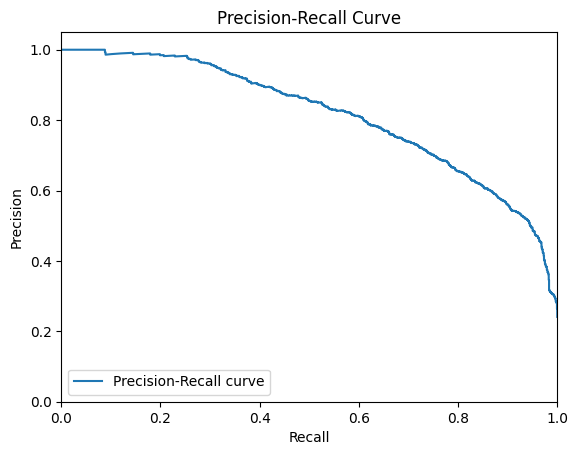

In [86]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("xgb", models["XGBoost"]),
    ],
    voting="soft" # voting='hard' / voting='soft', weights=[2, 1, 2,1]
)

voting_model.fit(X_train, y_train)
voting_train_pred = voting_model.predict(X_train)
voting_test_pred = voting_model.predict(X_test)


cm = confusion_matrix(y_test, voting_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
             xticklabels=['<=50K', '>50K'],
             yticklabels=['<=50K', '>50K'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(
    y_test, voting_test_pred,
    target_names=['<=50K', '>50K'],
    zero_division=0
))

y_pred_prob = voting_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Voting Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, voting_train_pred),
    "Test Accuracy": accuracy_score(y_test, voting_test_pred),
    "Train Precision": precision_score(y_train, voting_train_pred, zero_division=0),
    "Test Precision": precision_score(y_test, voting_test_pred, zero_division=0),
    "Train Recall": recall_score(y_train, voting_train_pred, zero_division=0),
    "Test Recall": recall_score(y_test, voting_test_pred, zero_division=0),
    "Train F1 Score": f1_score(y_train, voting_train_pred, zero_division=0),
    "Test F1 Score": f1_score(y_test, voting_test_pred, zero_division=0),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, voting_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, voting_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Confusion Matrix:
 [[4470  470]
 [ 552 1016]]


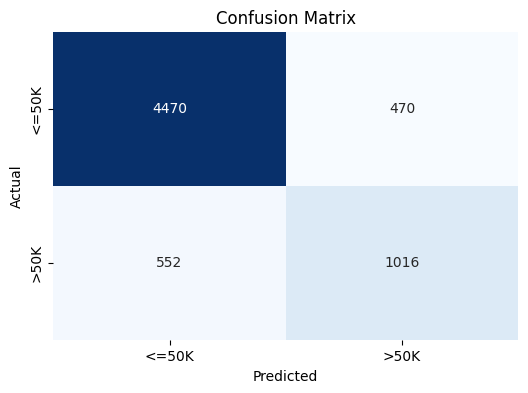


Classification Report:

              precision    recall  f1-score   support

       <=50K       0.89      0.90      0.90      4940
        >50K       0.68      0.65      0.67      1568

    accuracy                           0.84      6508
   macro avg       0.79      0.78      0.78      6508
weighted avg       0.84      0.84      0.84      6508

ROC-AUC: 0.8997624555895233


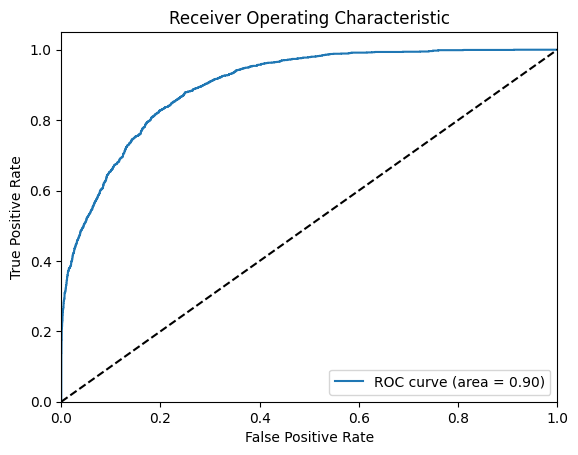

PR AUC: 0.7669572549034814


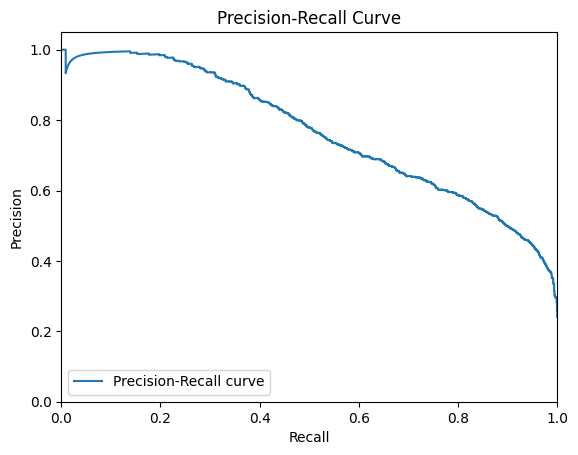

In [87]:
stack_auto = StackingClassifier(
    estimators=[
        ("lr", models["Logistic Regression"]),
        ("rf", models["Random Forest"]),
        ("nb", models["Naive Bayes"]),
        ("lgbm", models["LightGBM"]),
    ],
    final_estimator=XGBClassifier(n_estimators=2000),
    stack_method="predict_proba",
    n_jobs=-1
)

# Train
stack_auto.fit(X_train, y_train)

# Predictions
stack_auto_train_pred = stack_auto.predict(X_train)
stack_auto_test_pred  = stack_auto.predict(X_test)

cm = confusion_matrix(y_test, stack_auto_test_pred)
print("\nConfusion Matrix:\n", cm)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap='Blues', cbar=False,
             xticklabels=['<=50K', '>50K'],
             yticklabels=['<=50K', '>50K'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

# Full classification report
print("\nClassification Report:\n")
print(classification_report(
    y_test, stack_auto_test_pred,
    target_names=['<=50K', '>50K'],
    zero_division=0
))

y_pred_prob = stack_auto.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_pred_prob)
print("ROC-AUC:", roc_auc)

# ROC curve
fpr, tpr, roc_thresholds = roc_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = {:.2f})'.format(roc_auc))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

pr_auc = average_precision_score(y_test, y_pred_prob)
print("PR AUC:", pr_auc)

precision_vals, recall_vals, pr_thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure()
plt.plot(recall_vals, precision_vals, label='Precision-Recall curve')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend(loc="lower left")
plt.show()

results["Stacking Classifier"] = {
    "Train Accuracy": accuracy_score(y_train, stack_auto_train_pred),
    "Test Accuracy": accuracy_score(y_test, stack_auto_test_pred),
    "Train Precision": precision_score(y_train, stack_auto_train_pred, zero_division=0),
    "Test Precision": precision_score(y_test, stack_auto_test_pred, zero_division=0),
    "Train Recall": recall_score(y_train, stack_auto_train_pred, zero_division=0),
    "Test Recall": recall_score(y_test, stack_auto_test_pred, zero_division=0),
    "Train F1 Score": f1_score(y_train, stack_auto_train_pred, zero_division=0),
    "Test F1 Score": f1_score(y_test, stack_auto_test_pred, zero_division=0),
    "Train Balanced Accuracy": balanced_accuracy_score(y_train, stack_auto_train_pred),
    "Test Balanced Accuracy": balanced_accuracy_score(y_test, stack_auto_test_pred),
    "ROC-AUC": roc_auc,
    "PR AUC": pr_auc
}

In [88]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values(by="Test F1 Score", ascending=False)
results_df

,Train Accuracy,Test Accuracy,Train Precision,Test Precision,Train Recall,Test Recall,Train F1 Score,Test F1 Score,Train Balanced Accuracy,Test Balanced Accuracy,ROC-AUC,PR AUC
Voting Classifier,0.929694,0.854179,0.805728,0.667569,0.933185,0.786352,0.864785,0.722108,0.930885,0.831030,0.920860,0.814645
Hist Gradient Boosting,0.883515,0.873233,0.803561,0.783371,0.683623,0.654974,0.738756,0.713442,0.815291,0.798742,0.930593,0.829420
XGBoost,0.901110,0.872157,0.843014,0.776692,0.724446,0.658801,0.779245,0.712905,0.840814,0.799340,0.931153,0.831401
CatBoost,0.898037,0.872465,0.842584,0.784722,0.709297,0.648597,0.770216,0.710196,0.833619,0.796060,0.933018,0.834413
LightGBM,0.888624,0.870313,0.817873,0.779321,0.691756,0.644133,0.749546,0.705307,0.821432,0.793119,0.931247,0.830833
Gradient Boosting,0.869876,0.866318,0.801044,0.794266,0.611864,0.600765,0.693789,0.684096,0.781815,0.775686,0.925708,0.818454
Random Forest,0.999923,0.853411,0.999841,0.735069,0.999841,0.612245,0.999841,0.668058,0.999895,0.771102,0.905937,0.769569
Stacking Classifier,0.853894,0.842963,0.714087,0.683715,0.656355,0.647959,0.684005,0.665357,0.786473,0.776409,0.899762,0.766957
SVC,0.865611,0.856792,0.790123,0.770869,0.602137,0.577168,0.683439,0.660102,0.775686,0.761357,0.904797,0.772972
Logistic Regression,0.851627,0.851567,0.739701,0.738133,0.592728,0.595026,0.658109,0.658898,0.763264,0.764011,0.911488,0.772367


<Axes: >

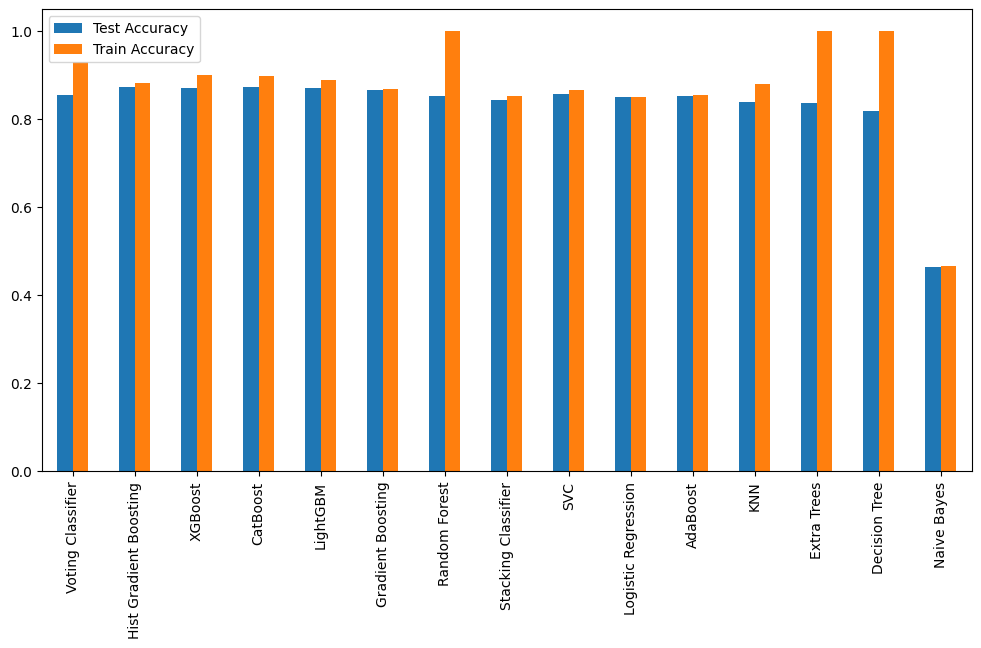

In [89]:
results_df[["Test Accuracy", "Train Accuracy"]].plot.bar(figsize=(12,6))

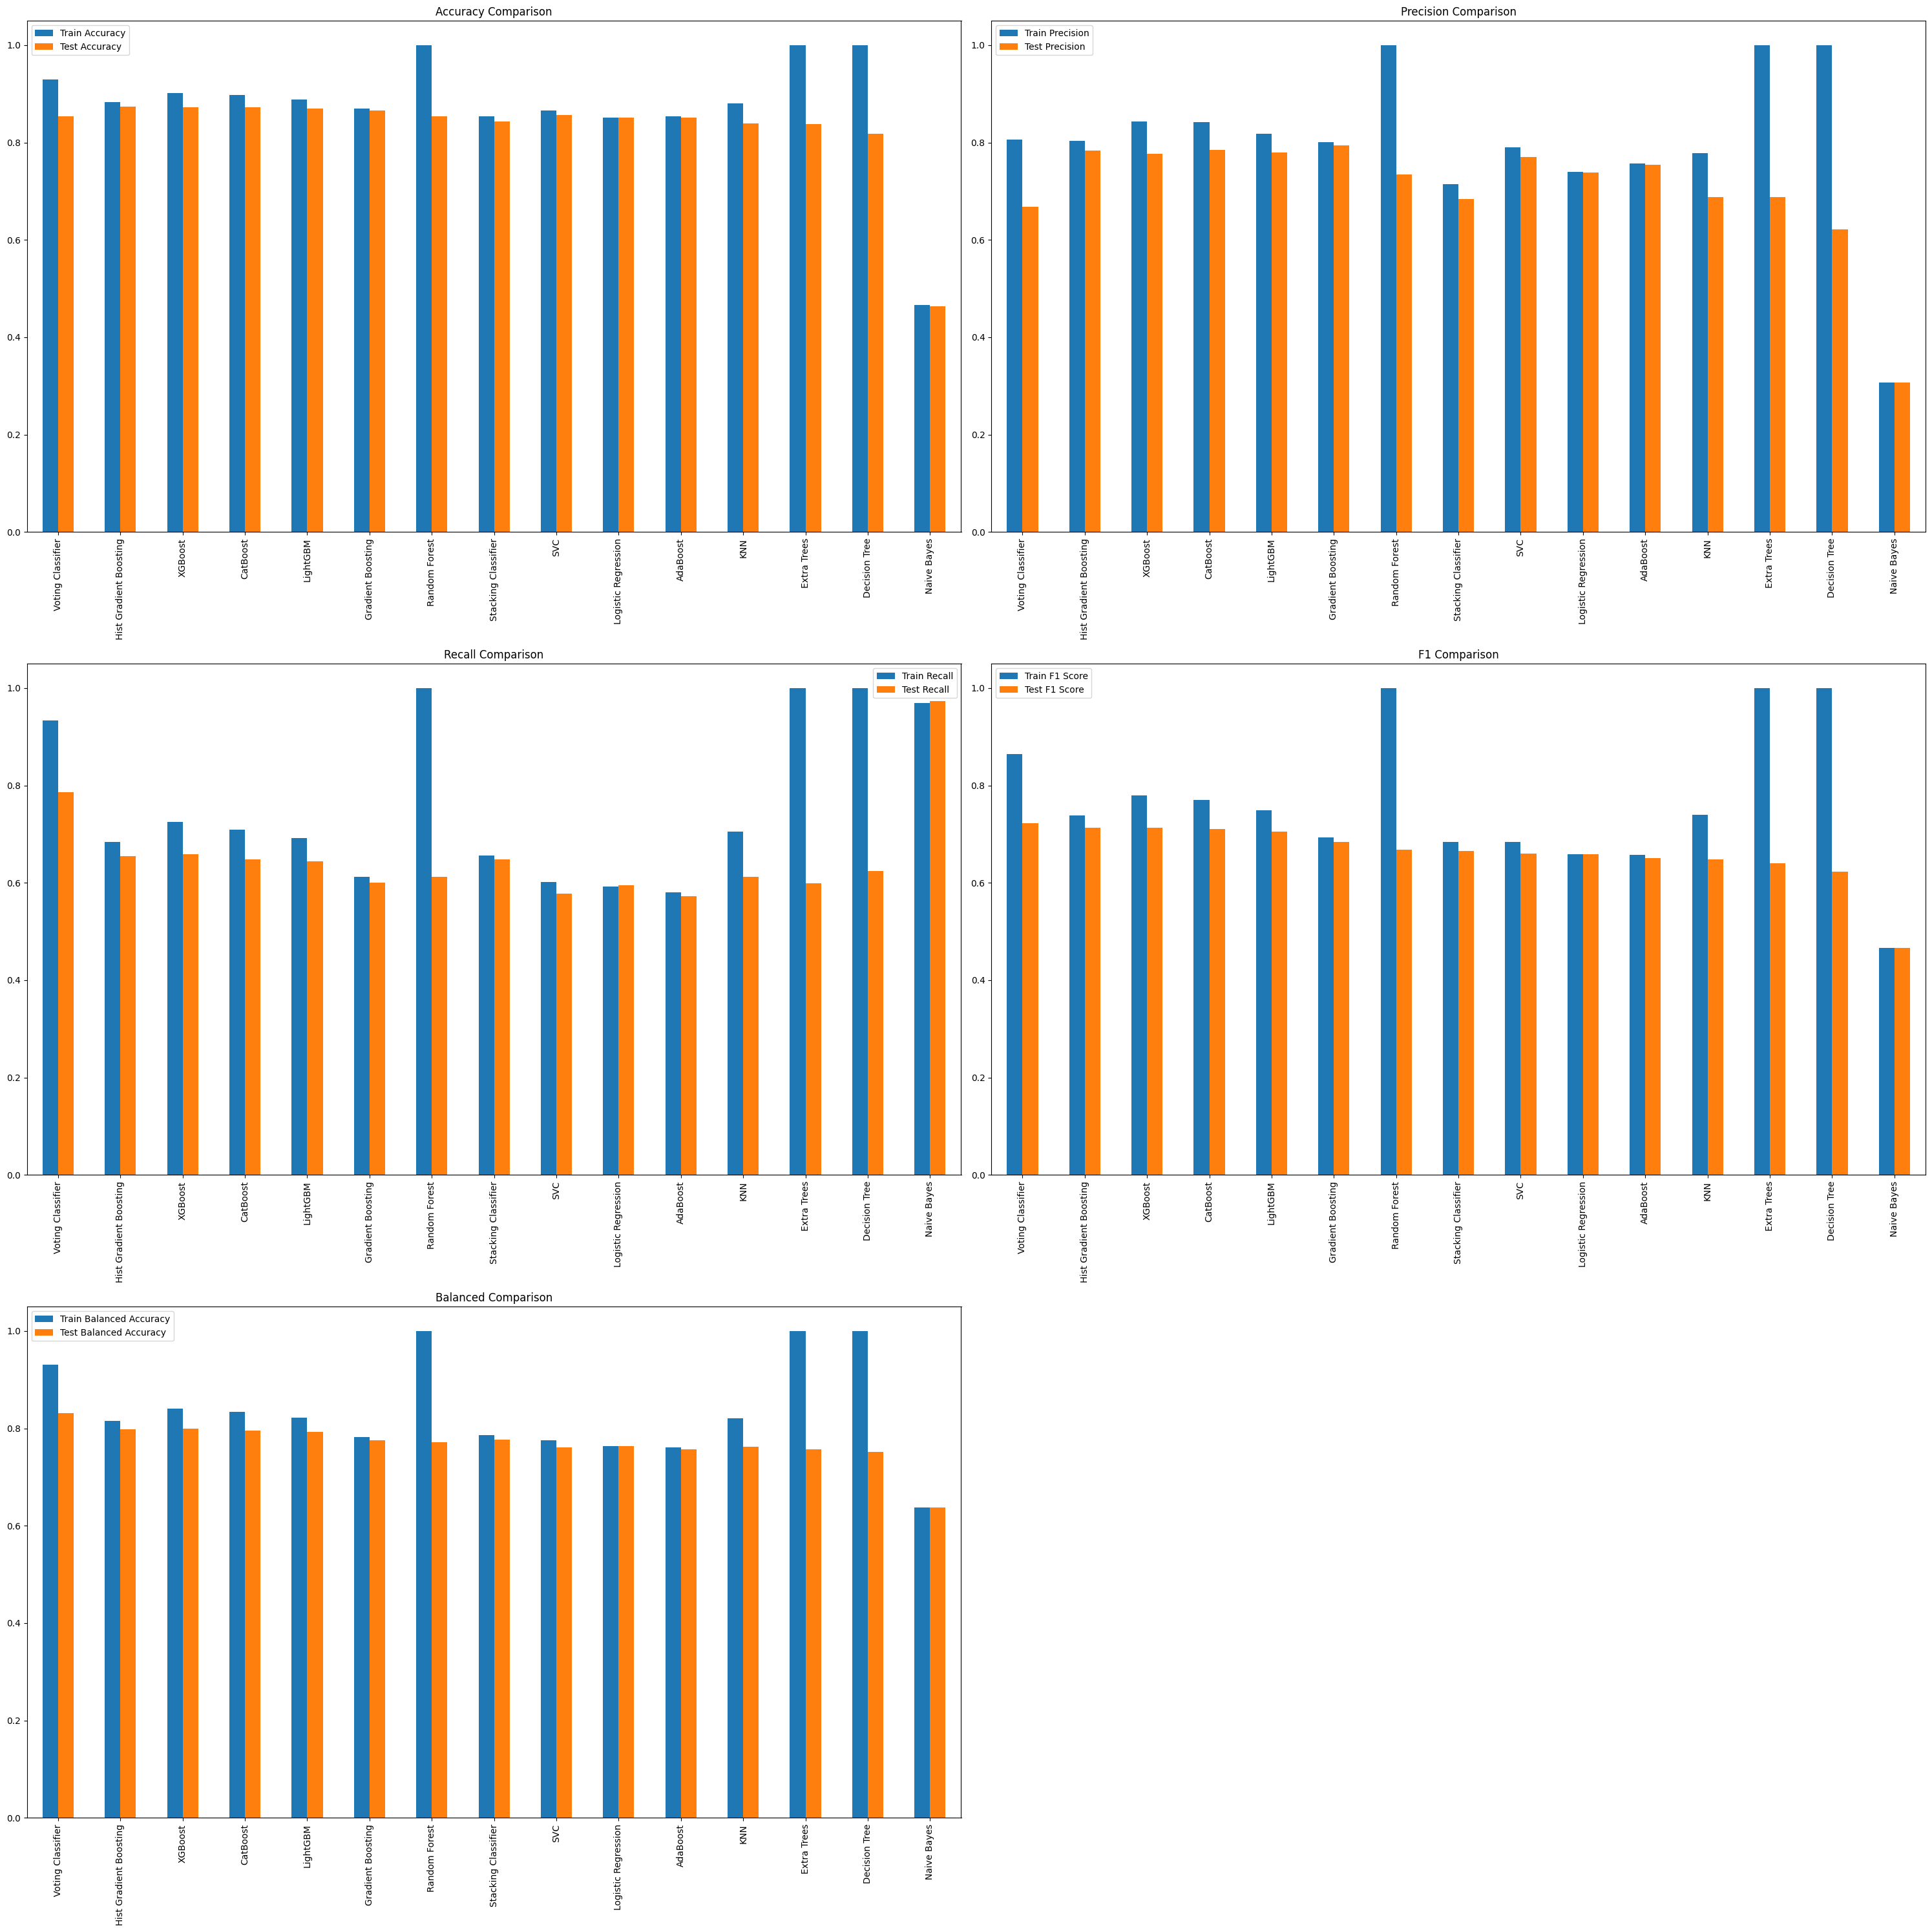

In [90]:
cols = [
    ['Train Accuracy', 'Test Accuracy'],
    ['Train Precision', 'Test Precision'],
    ['Train Recall', 'Test Recall'],
    ['Train F1 Score', 'Test F1 Score'],
    ["Train Balanced Accuracy", "Test Balanced Accuracy"]
]

plt.figure(figsize=(30,30))

for i, col in enumerate(cols):
    ax = plt.subplot(3, 2, i+1)
    results_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[1] + ' Comparison')

plt.tight_layout()
plt.show()